<center>

# High Copper GaAs Series with Many Twins

</center>

In [9]:
# ================================================================================================== Import =================================================================================================================
import re
import hyperspy.api as hs
import matplotlib.pyplot as plt
import numpy as np
from organized.k_factors import k_factors
from scipy.optimize import curve_fit
from datetime import datetime
from pathlib import Path
from matplotlib.ticker import MultipleLocator

In [11]:
# ==================================================================================================Load Data with Path ==================================================================================================

MainPath = Path(r"C:\Users\grego\OneDrive\Dokumente\STUDIUM\PHYSIK\2026-2027_Masterthesis\Jeol_JEM_2100_LaB6_Data\2026-05-29-GaAs-SC5-A3\EDS")

folder = MainPath / "MSA\\OffZone"
PlotPath = MainPath / "Plots"

def extract_angle(filepath):
    name = Path(filepath).stem   # e.g. "+1.5D" -> "+1.5D"
    match = re.search(r'([+-]?\d+(?:\.\d+)?)D', name)
    if match is None:
        raise ValueError(f"Could not extract angle from filename: {name}")
    return float(match.group(1))

# load and SORT files by angle
files = sorted(folder.glob("*.msa"), key=extract_angle)



C:\Users\grego\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
C:\Users\grego\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\hyperspy\misc\_utils.py:1590: VisibleDeprecationWarning: Importing `LazyComplexSignal1D` from `hyperspy._signals.complex_signal1d` is deprecated and will be removed in the HyperSpy 3.0 release. Import it from `hyperspy.signals` instead.
  warnings.warn(
C:\Users\grego\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\hyperspy\misc\_utils.py:1590: VisibleDeprecationWarning: Importing `LazySignal1D` from `hyperspy._signals.signal1d` is depre

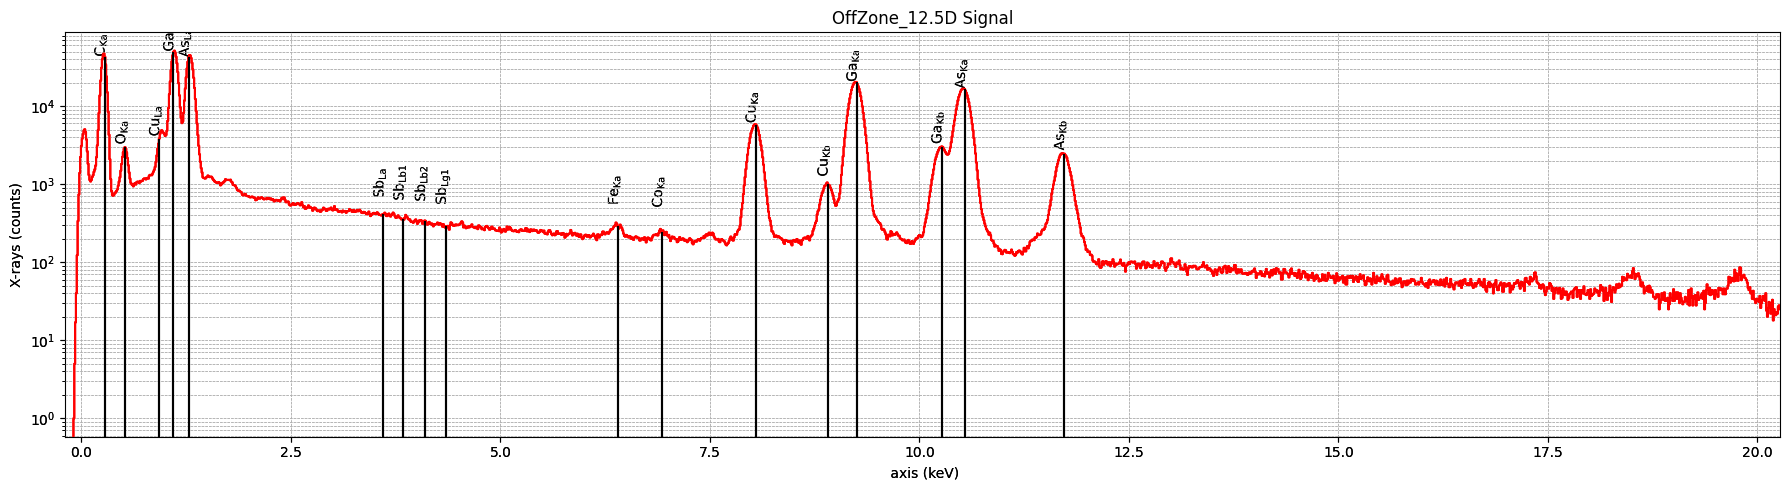

In [12]:
# ================================================================================================== Identify Peaks =================================================================================================================

s = hs.load(files[5]) # Load one spectrum to identify peaks and set elements/lines for all spectra
s.set_elements(['Ga', 'As', 'Sb', 'Cu', 'Fe', 'Co', 'O', 'C'])
s.set_lines(['Ga_Ka', 'Ga_Kb', 'Ga_La', 'As_Ka', 'As_Kb', 'As_La', 'Sb_La', 'Sb_Lb1', 'Sb_Lb2', 'Sb_Lg1', 'Cu_Ka', 'Cu_Kb', 'Cu_La'])

s.plot(True)
fig = plt.gcf()
ax = plt.gca()
ax.grid(True, which="both", ls="--", lw=0.5)
ax.set_yscale("log") # Set y-axis to "linear", "log" or"symlog", scale for better visibility of peaks
fig.set_size_inches(18, 5)
fig.tight_layout()


<center>

# Background Window Positioning
</center>

Is the Background Window (bw) good?

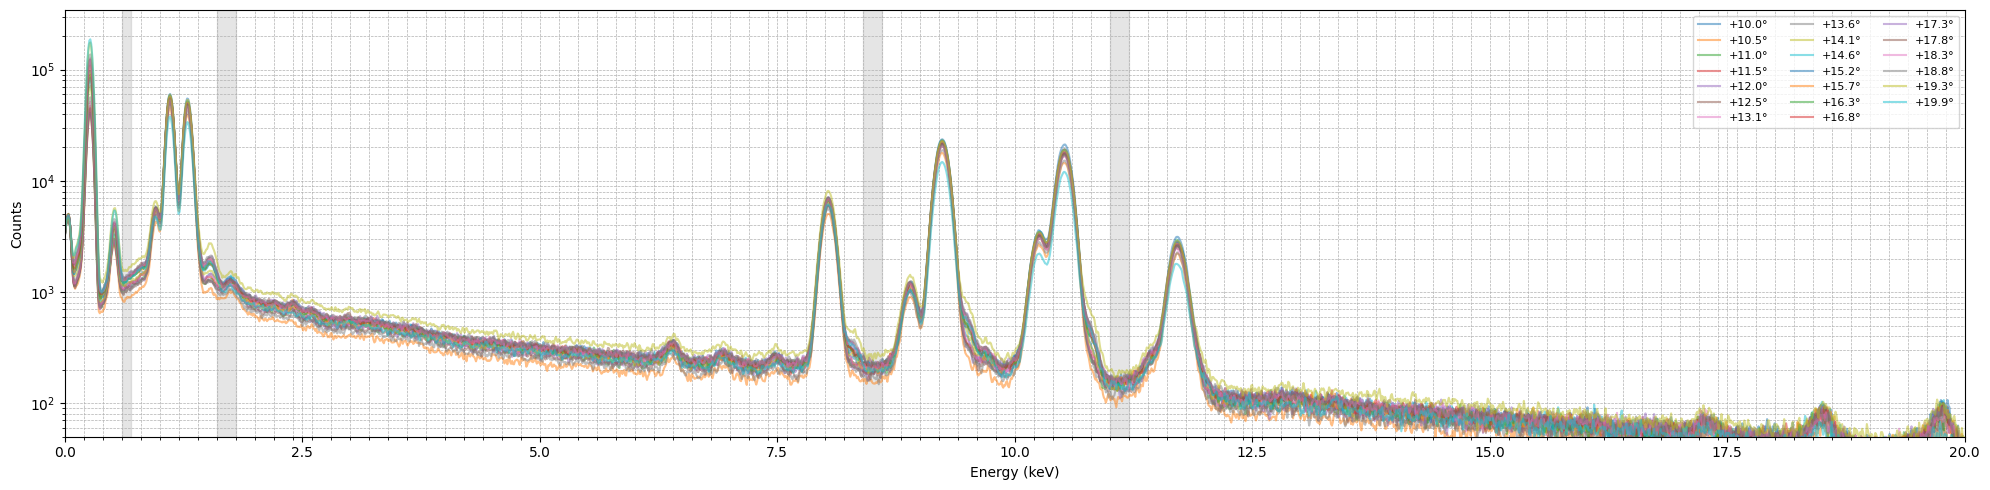

In [13]:
#=================================================================================================== Background Window Control =================================================================================================================

fig, ax = plt.subplots(figsize=(20, 5))

for i, f in enumerate(files):
    s = hs.load(f)
    s.set_signal_type("EDS_TEM")
    s.set_elements(['Ga', 'As'])
    s.set_lines(['Ga_Ka', 'As_Ka', 'Ga_La', 'As_La'])

    x = s.axes_manager.signal_axes[0].axis
    y = s.data.astype(float)

    # bw = s.estimate_background_windows(line_width=[5.0, 3.0])

    #  # Ga_Ka region
    # lmin_Ga_K, lmax_Ga_K = 9.0, 9.2
    # rmin_Ga_K, rmax_Ga_K = 9.4, 9.6

    #Ka region
    lmin_K, lmax_K = 8.4, 8.6
    rmin_K, rmax_K = 11.0, 11.2

    # Ga_La / As_La region
    lmin_L, lmax_L = 0.6, 0.7
    rmin_L, rmax_L = 1.6, 1.8

    angle = extract_angle(f)

    ax.plot(x, y, label=f"{angle:+}°", alpha=0.5)

    # draw bw only once, because they are identical for all spectra
    if i == 0:
        # Ga_K peak windows
        # ax.axvspan(lmin_Ga_K, lmax_Ga_K, color="grey", alpha=0.2, label="background window")
        # ax.axvspan(rmin_Ga_K, rmax_Ga_K, color="grey", alpha=0.2)

        # As_K peak windows
        ax.axvspan(lmin_K, lmax_K, color="grey", alpha=0.2)
        ax.axvspan(rmin_K, rmax_K, color="grey", alpha=0.2)

        # L peak windows
        ax.axvspan(lmin_L, lmax_L, color="grey", alpha=0.2)
        ax.axvspan(rmin_L, rmax_L, color="grey", alpha=0.2)

ax.set_yscale("log")
ax.set_ylim(bottom=50) # Set y-axis limits to better visualize peaks, adjust as needed
ax.xaxis.set_minor_locator(MultipleLocator(0.2))
ax.grid(True, which="both", ls="--", lw=0.5)
ax.set_xlabel("Energy (keV)")
ax.set_ylabel("Counts")
ax.set_xlim(0,20) # Set x-axis limits to focus on relevant energy range, adjust as needed
ax.legend(ncol=3, fontsize=8)
fig.tight_layout()
plt.show()

<center>

# Gaussien Composition & Peakarea Calculation
</center>


Gaussien Composition & Peakarea Calculation K-Factor were uptdated 

Each peak needs 10^4 counts after Background substraction to be a good peak according to Willliams & Cater

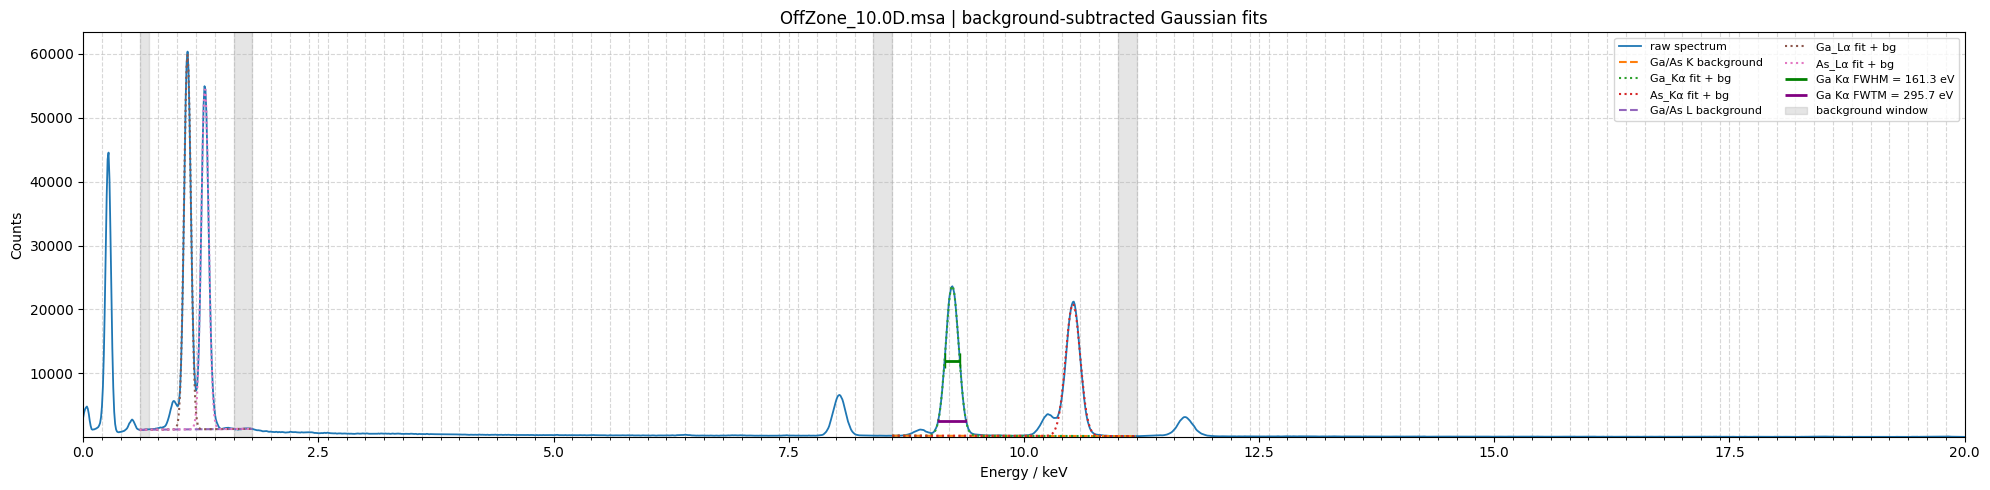

OffZone_10.0D.msa Cu_Kb=8.9024 keV, Ga_Ka=9.2373 keV, As_Ka=10.5211 keV, Ga_La=1.1088 keV, As_La=1.2949 keV, Cu_Kb=17561.1 Counts/Peak, Ga_Ka=405238.3 Counts/Peak, As_Ka=399739.5 Counts/Peak, Ga_La=538128.5 Counts/Peak, As_La=525332.1 Counts/Peak


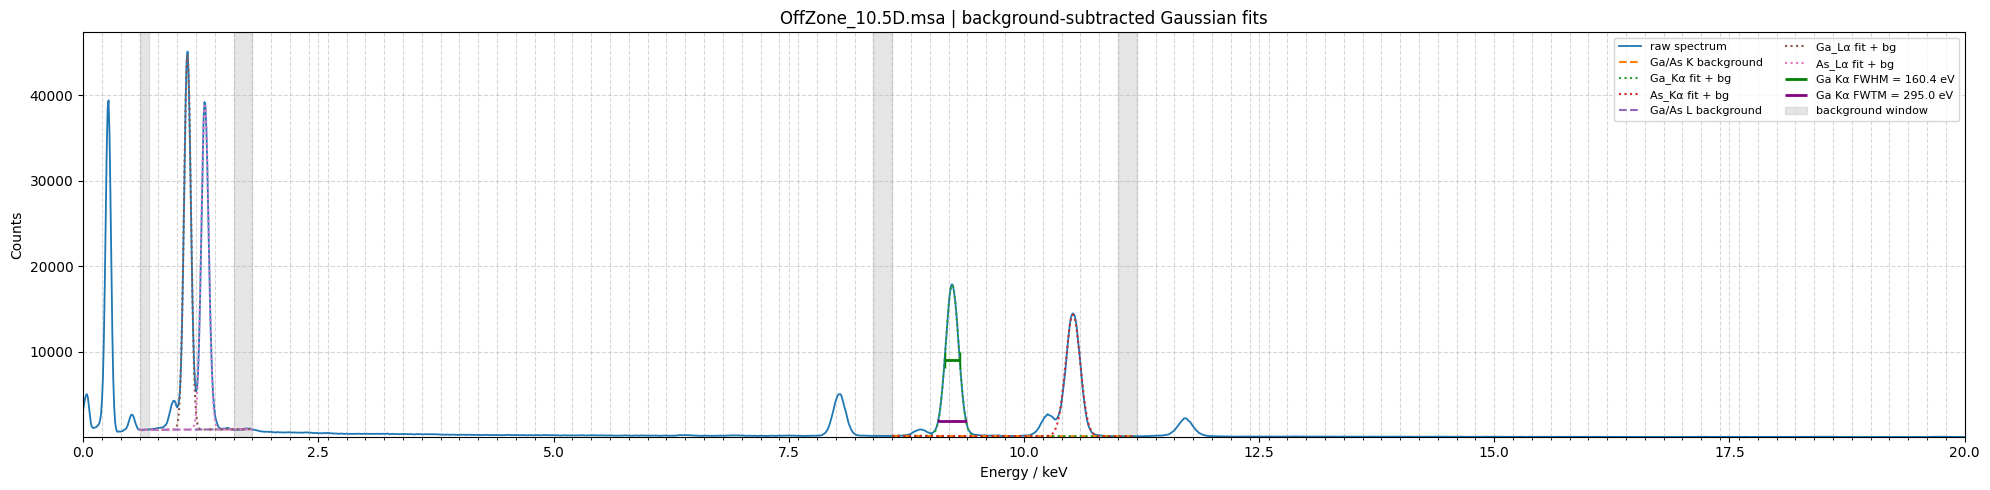

OffZone_10.5D.msa Cu_Kb=8.9028 keV, Ga_Ka=9.2374 keV, As_Ka=10.5210 keV, Ga_La=1.1087 keV, As_La=1.2949 keV, Cu_Kb=13907.5 Counts/Peak, Ga_Ka=303606.8 Counts/Peak, As_Ka=277118.1 Counts/Peak, Ga_La=403031.8 Counts/Peak, As_La=375139.9 Counts/Peak


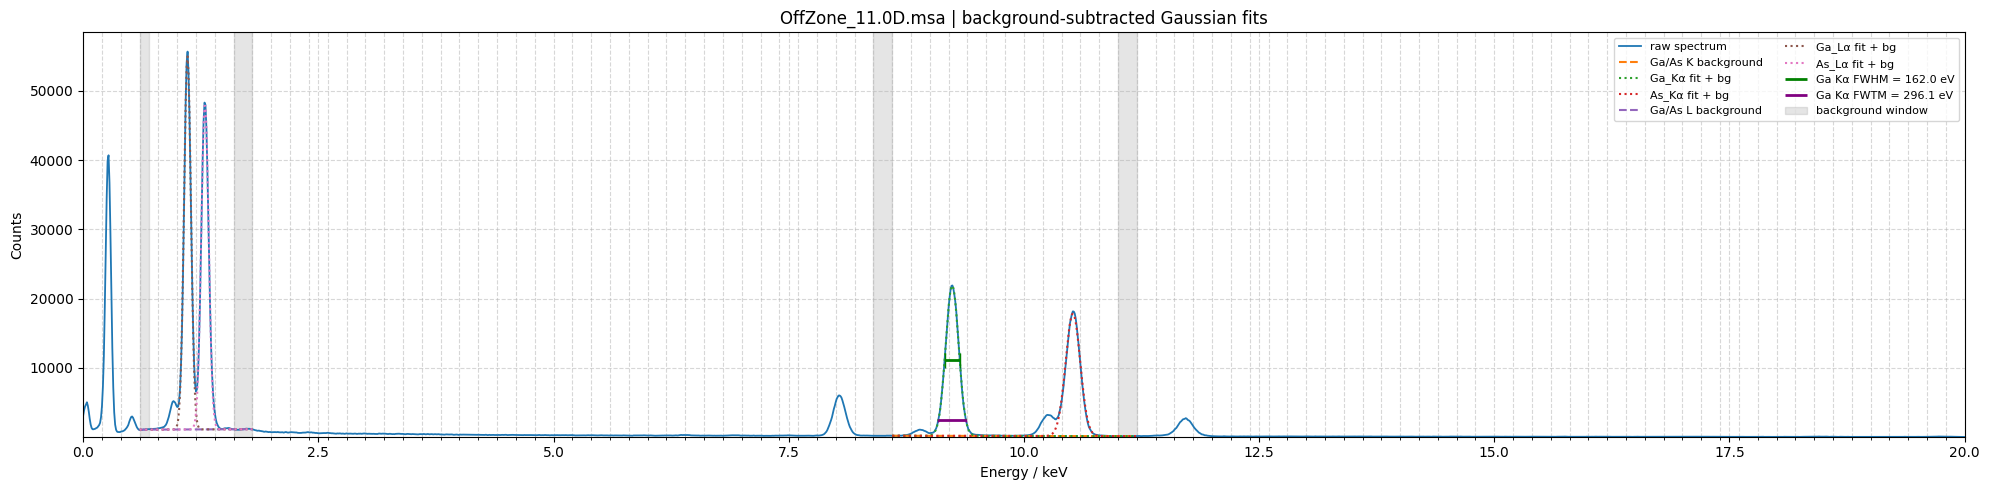

OffZone_11.0D.msa Cu_Kb=8.9008 keV, Ga_Ka=9.2374 keV, As_Ka=10.5209 keV, Ga_La=1.1090 keV, As_La=1.2949 keV, Cu_Kb=15938.0 Counts/Peak, Ga_Ka=373720.0 Counts/Peak, As_Ka=344325.0 Counts/Peak, Ga_La=496022.3 Counts/Peak, As_La=461569.1 Counts/Peak


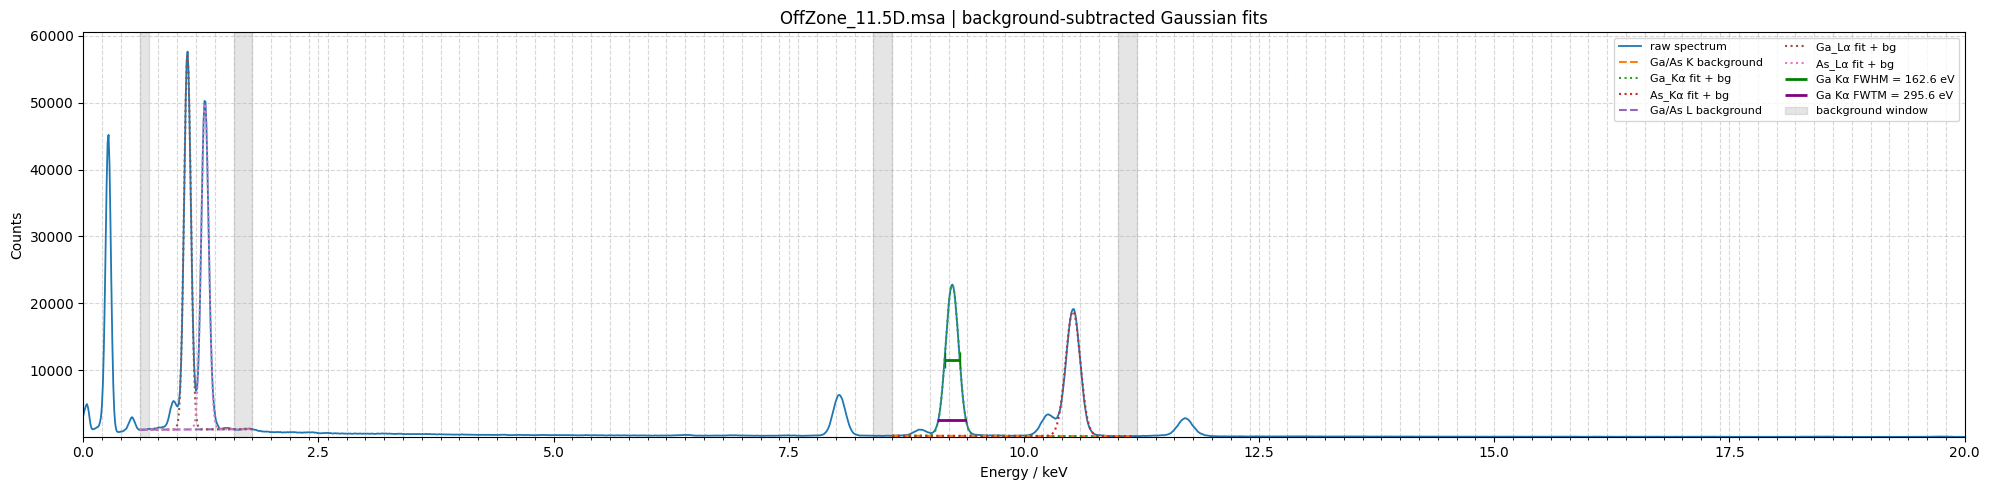

OffZone_11.5D.msa Cu_Kb=8.9031 keV, Ga_Ka=9.2374 keV, As_Ka=10.5210 keV, Ga_La=1.1088 keV, As_La=1.2950 keV, Cu_Kb=16938.7 Counts/Peak, Ga_Ka=390382.4 Counts/Peak, As_Ka=363123.8 Counts/Peak, Ga_La=513478.2 Counts/Peak, As_La=481744.9 Counts/Peak


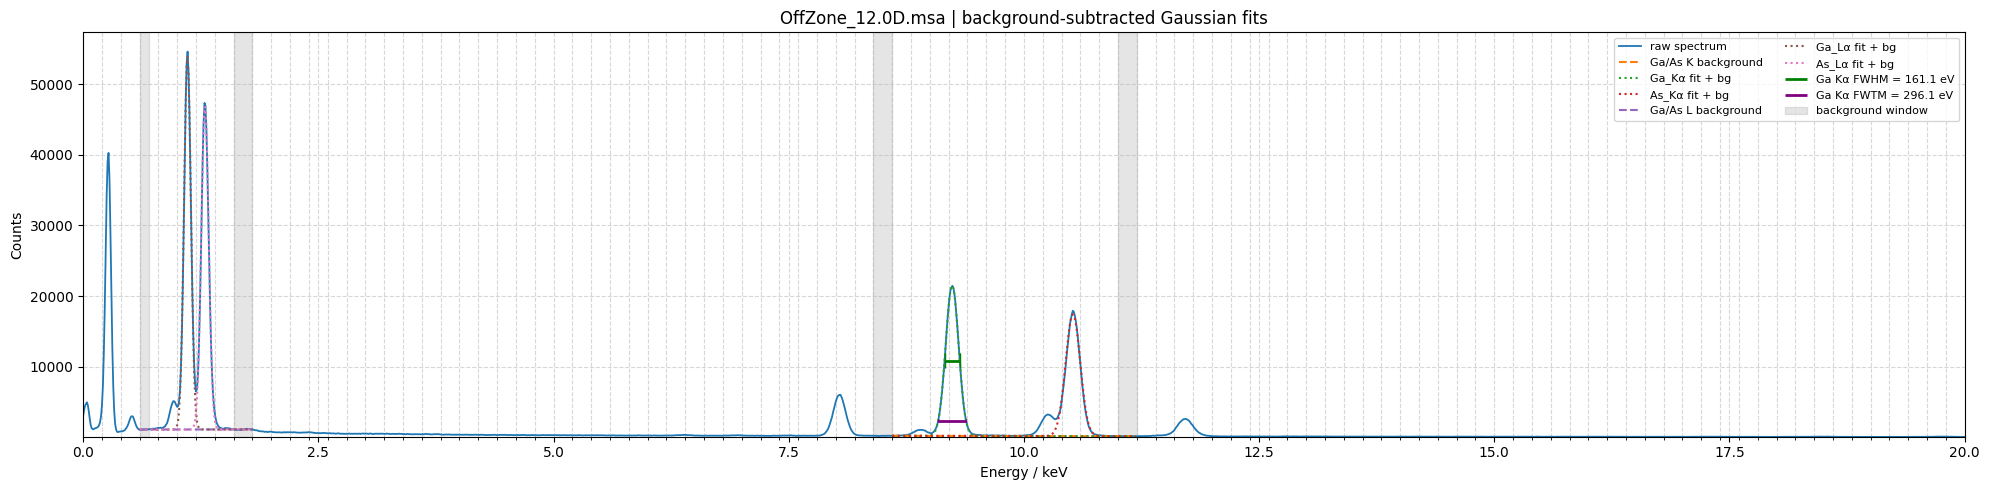

OffZone_12.0D.msa Cu_Kb=8.9033 keV, Ga_Ka=9.2371 keV, As_Ka=10.5209 keV, Ga_La=1.1089 keV, As_La=1.2949 keV, Cu_Kb=16337.6 Counts/Peak, Ga_Ka=367784.1 Counts/Peak, As_Ka=335728.7 Counts/Peak, Ga_La=485520.2 Counts/Peak, As_La=453439.1 Counts/Peak


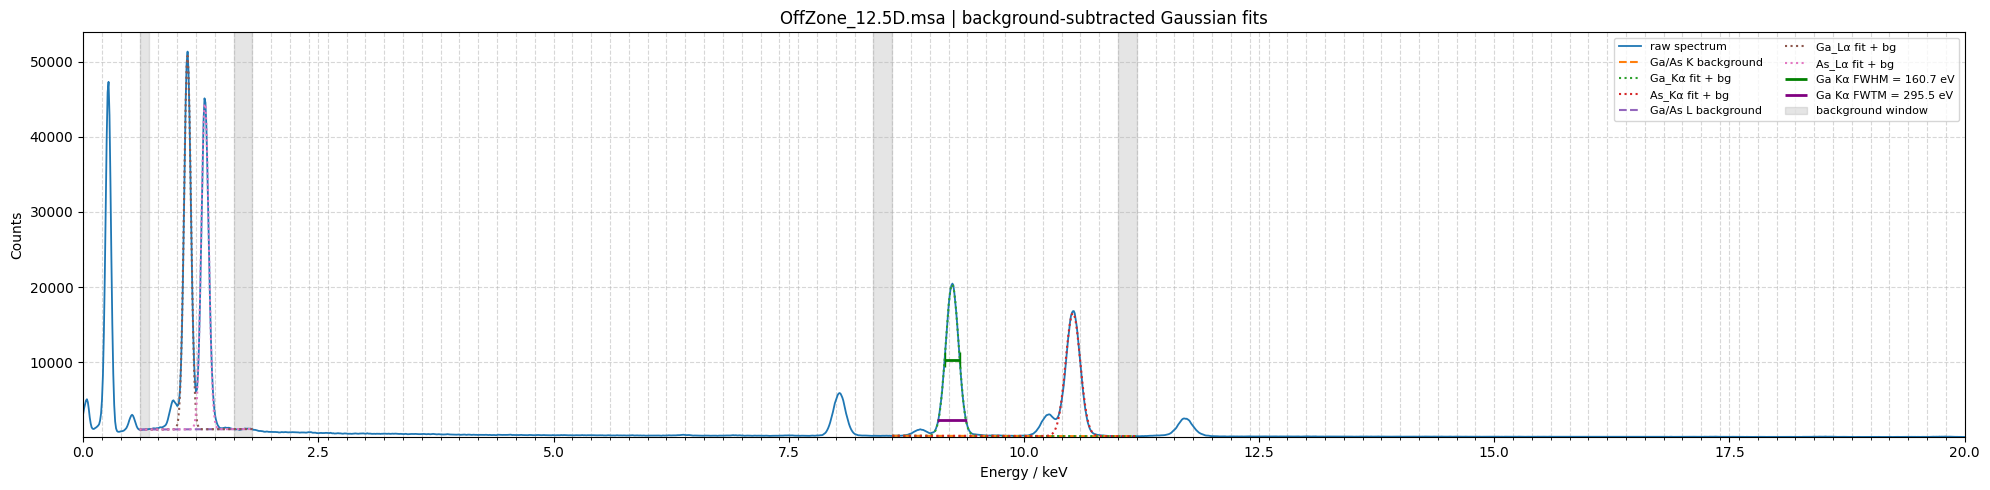

OffZone_12.5D.msa Cu_Kb=8.9014 keV, Ga_Ka=9.2372 keV, As_Ka=10.5211 keV, Ga_La=1.1089 keV, As_La=1.2949 keV, Cu_Kb=15487.7 Counts/Peak, Ga_Ka=347114.5 Counts/Peak, As_Ka=319314.2 Counts/Peak, Ga_La=457478.7 Counts/Peak, As_La=427441.9 Counts/Peak


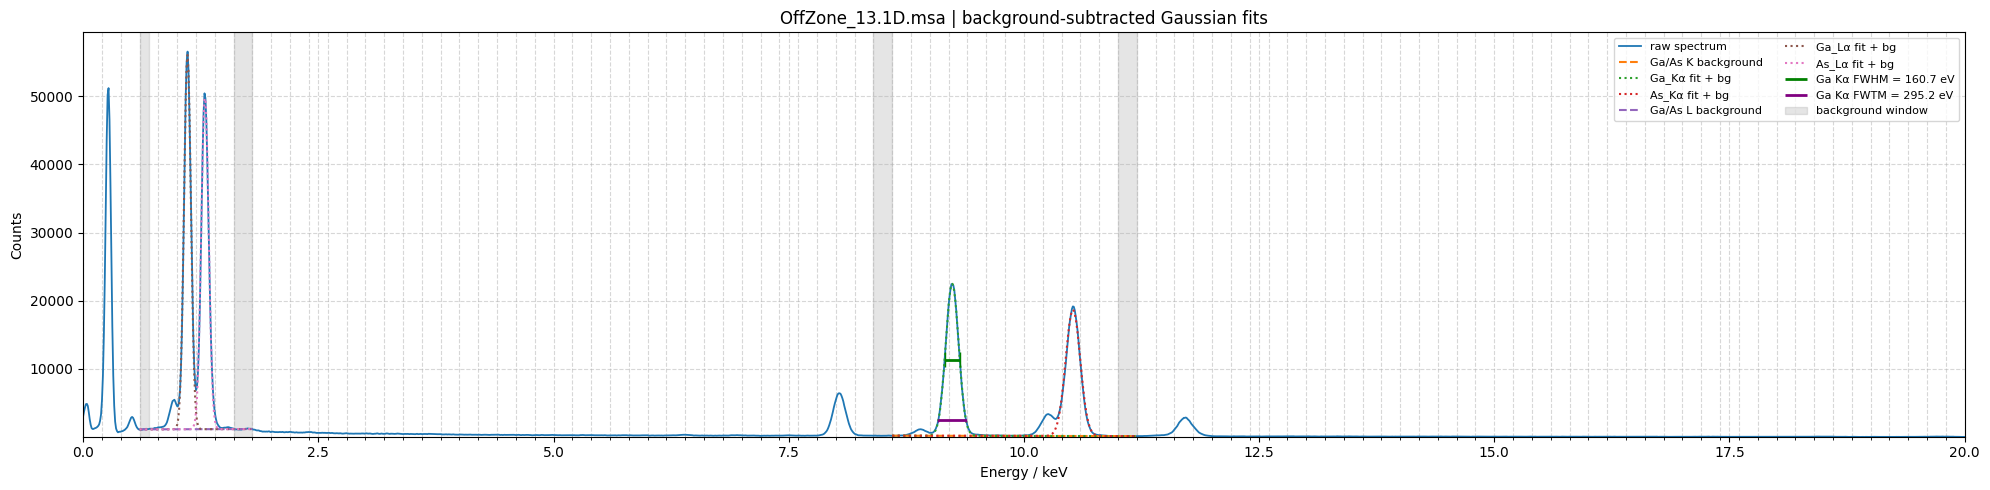

OffZone_13.1D.msa Cu_Kb=8.9038 keV, Ga_Ka=9.2376 keV, As_Ka=10.5213 keV, Ga_La=1.1088 keV, As_La=1.2949 keV, Cu_Kb=17189.4 Counts/Peak, Ga_Ka=383657.6 Counts/Peak, As_Ka=359462.1 Counts/Peak, Ga_La=505501.9 Counts/Peak, As_La=480150.1 Counts/Peak


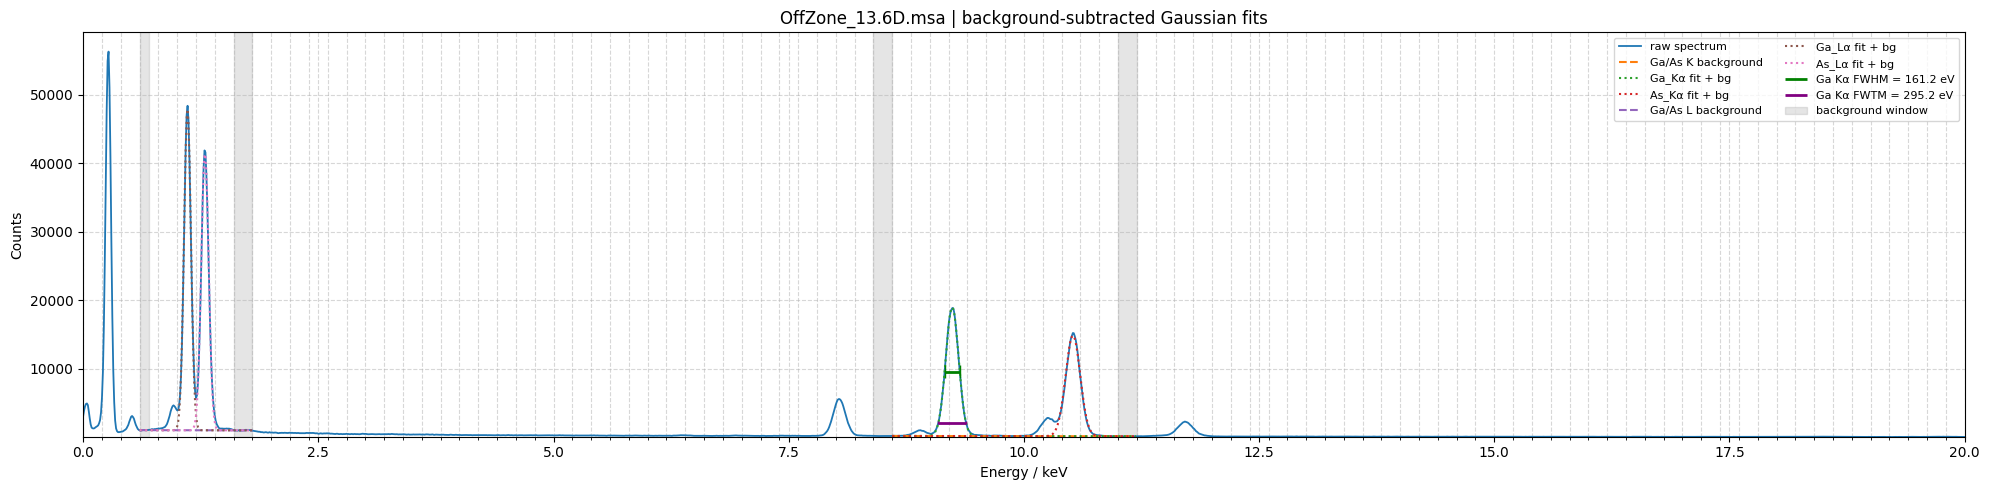

OffZone_13.6D.msa Cu_Kb=8.8997 keV, Ga_Ka=9.2376 keV, As_Ka=10.5209 keV, Ga_La=1.1089 keV, As_La=1.2949 keV, Cu_Kb=14659.3 Counts/Peak, Ga_Ka=324006.5 Counts/Peak, As_Ka=286867.1 Counts/Peak, Ga_La=431637.5 Counts/Peak, As_La=399570.7 Counts/Peak


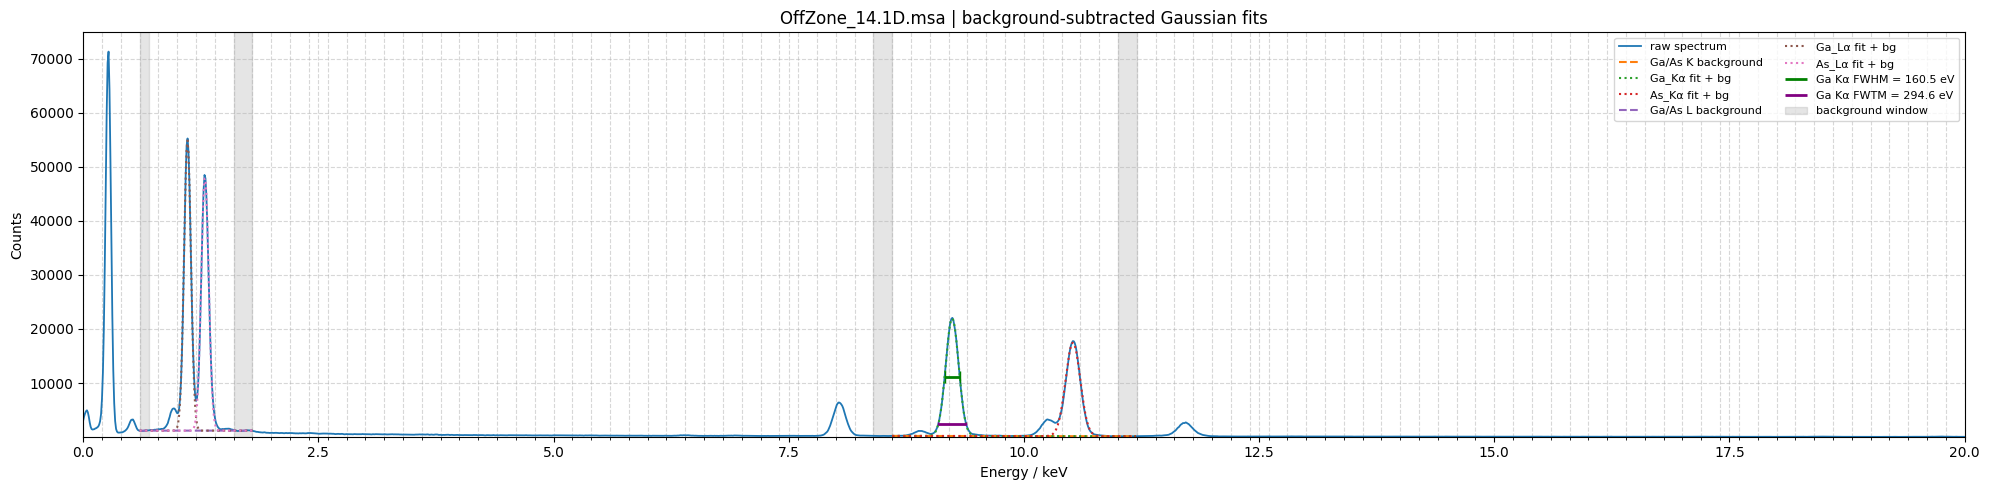

OffZone_14.1D.msa Cu_Kb=8.9013 keV, Ga_Ka=9.2376 keV, As_Ka=10.5211 keV, Ga_La=1.1089 keV, As_La=1.2949 keV, Cu_Kb=16860.1 Counts/Peak, Ga_Ka=375126.0 Counts/Peak, As_Ka=338321.9 Counts/Peak, Ga_La=494247.6 Counts/Peak, As_La=464418.3 Counts/Peak


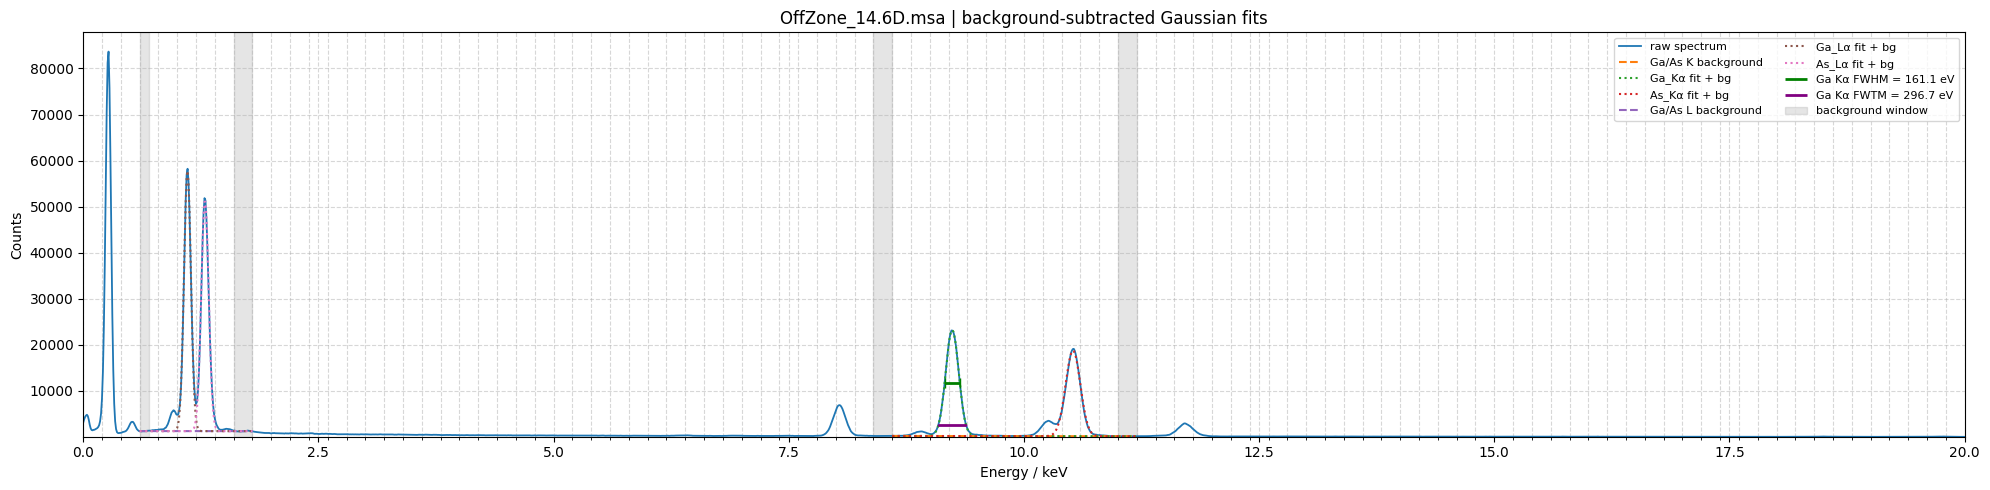

OffZone_14.6D.msa Cu_Kb=8.9021 keV, Ga_Ka=9.2379 keV, As_Ka=10.5215 keV, Ga_La=1.1088 keV, As_La=1.2951 keV, Cu_Kb=18070.3 Counts/Peak, Ga_Ka=398145.1 Counts/Peak, As_Ka=363873.8 Counts/Peak, Ga_La=520884.4 Counts/Peak, As_La=496550.5 Counts/Peak


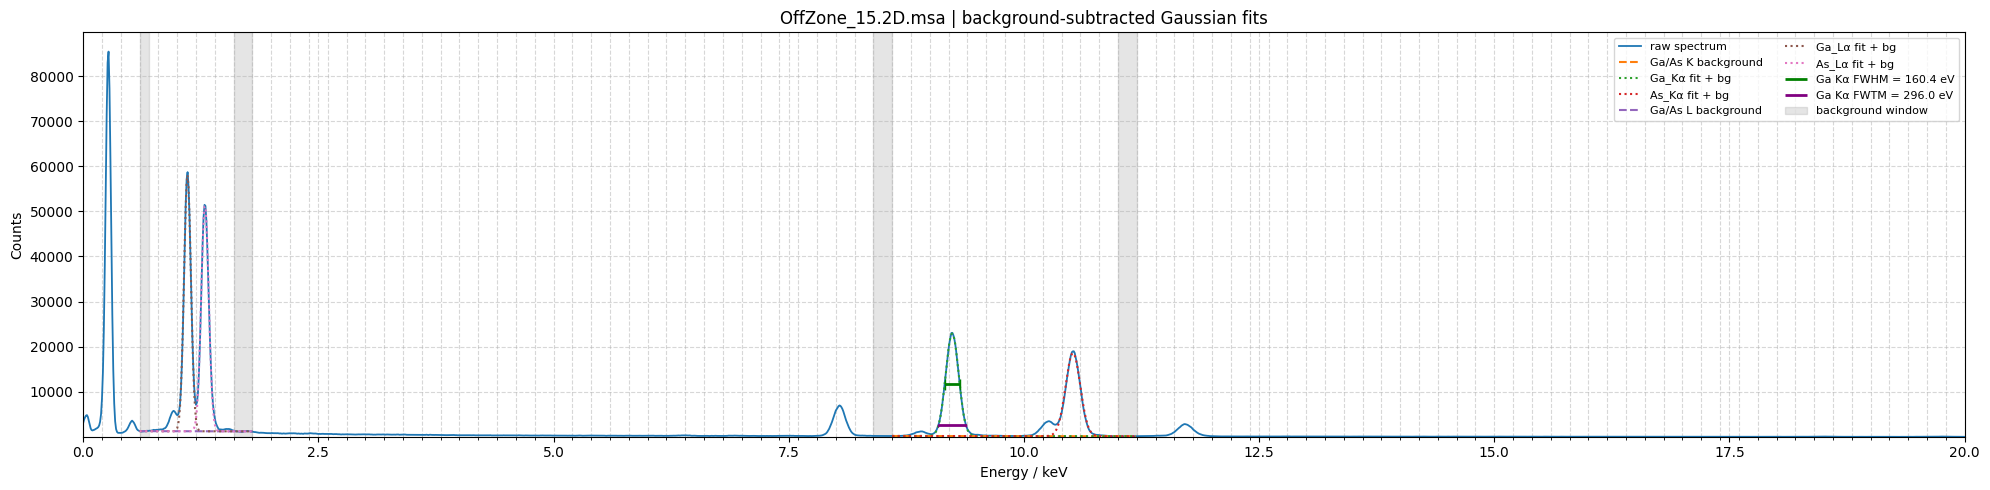

OffZone_15.2D.msa Cu_Kb=8.9039 keV, Ga_Ka=9.2377 keV, As_Ka=10.5212 keV, Ga_La=1.1089 keV, As_La=1.2950 keV, Cu_Kb=17919.2 Counts/Peak, Ga_Ka=391639.6 Counts/Peak, As_Ka=361035.3 Counts/Peak, Ga_La=521939.7 Counts/Peak, As_La=498648.4 Counts/Peak


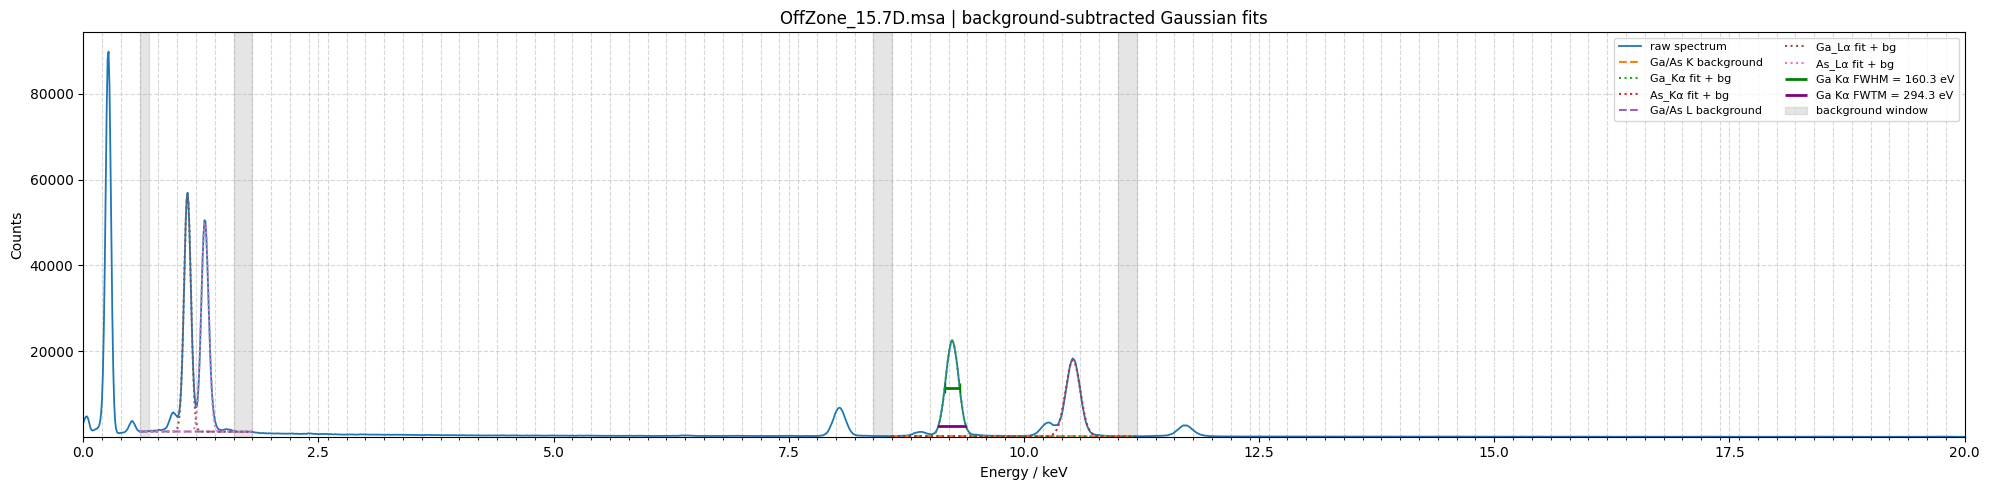

OffZone_15.7D.msa Cu_Kb=8.9010 keV, Ga_Ka=9.2373 keV, As_Ka=10.5208 keV, Ga_La=1.1089 keV, As_La=1.2950 keV, Cu_Kb=17843.5 Counts/Peak, Ga_Ka=382648.2 Counts/Peak, As_Ka=346422.7 Counts/Peak, Ga_La=509214.1 Counts/Peak, As_La=483849.0 Counts/Peak


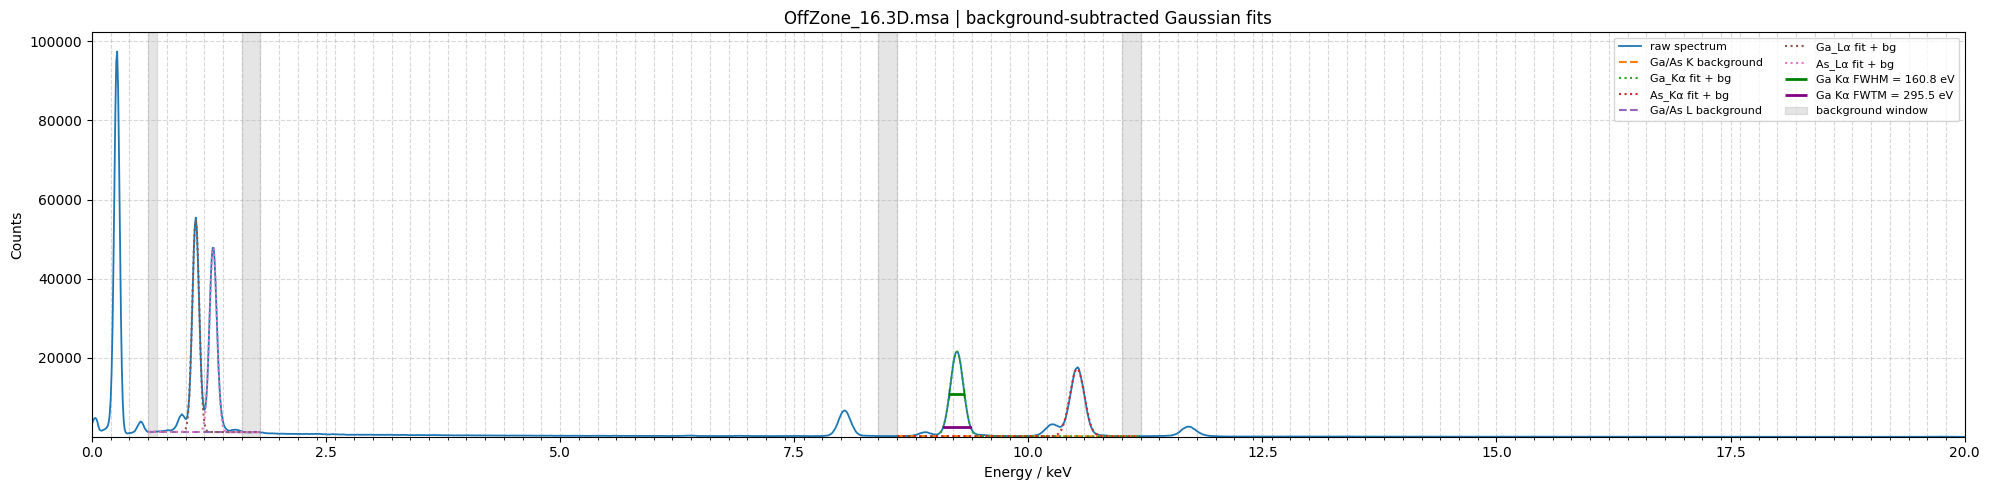

OffZone_16.3D.msa Cu_Kb=8.9013 keV, Ga_Ka=9.2374 keV, As_Ka=10.5210 keV, Ga_La=1.1090 keV, As_La=1.2952 keV, Cu_Kb=17196.6 Counts/Peak, Ga_Ka=369045.4 Counts/Peak, As_Ka=332772.3 Counts/Peak, Ga_La=494516.5 Counts/Peak, As_La=463211.7 Counts/Peak


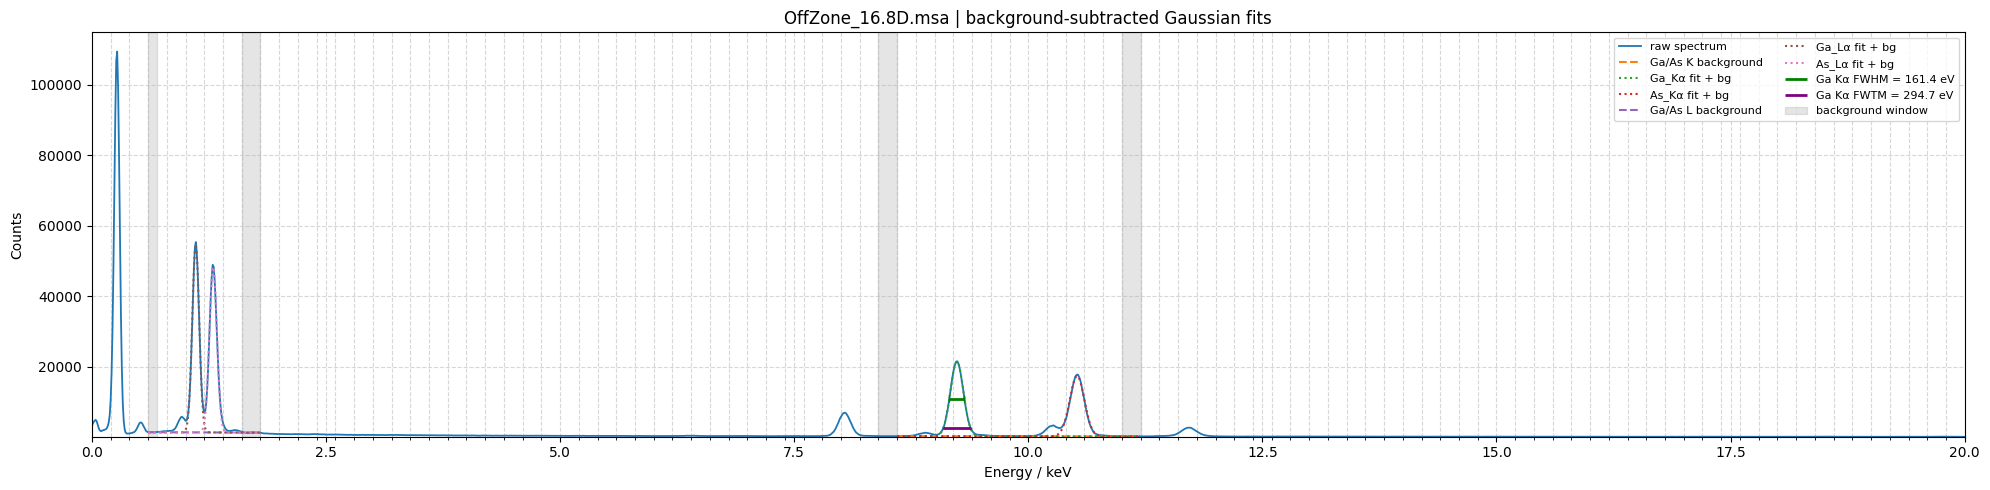

OffZone_16.8D.msa Cu_Kb=8.9017 keV, Ga_Ka=9.2373 keV, As_Ka=10.5208 keV, Ga_La=1.1089 keV, As_La=1.2951 keV, Cu_Kb=17591.1 Counts/Peak, Ga_Ka=367176.7 Counts/Peak, As_Ka=335940.7 Counts/Peak, Ga_La=492489.6 Counts/Peak, As_La=469905.2 Counts/Peak


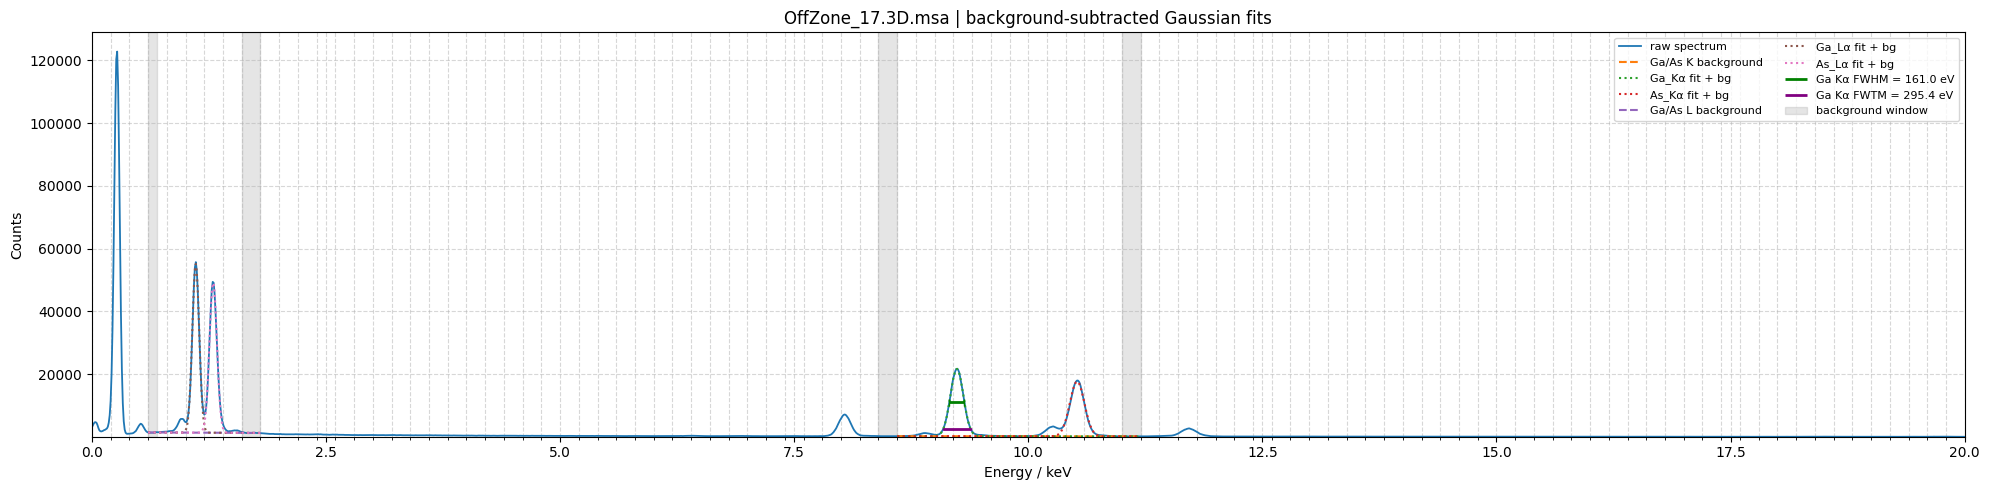

OffZone_17.3D.msa Cu_Kb=8.9023 keV, Ga_Ka=9.2375 keV, As_Ka=10.5216 keV, Ga_La=1.1091 keV, As_La=1.2953 keV, Cu_Kb=18031.2 Counts/Peak, Ga_Ka=371924.5 Counts/Peak, As_Ka=341251.3 Counts/Peak, Ga_La=496203.2 Counts/Peak, As_La=478064.7 Counts/Peak


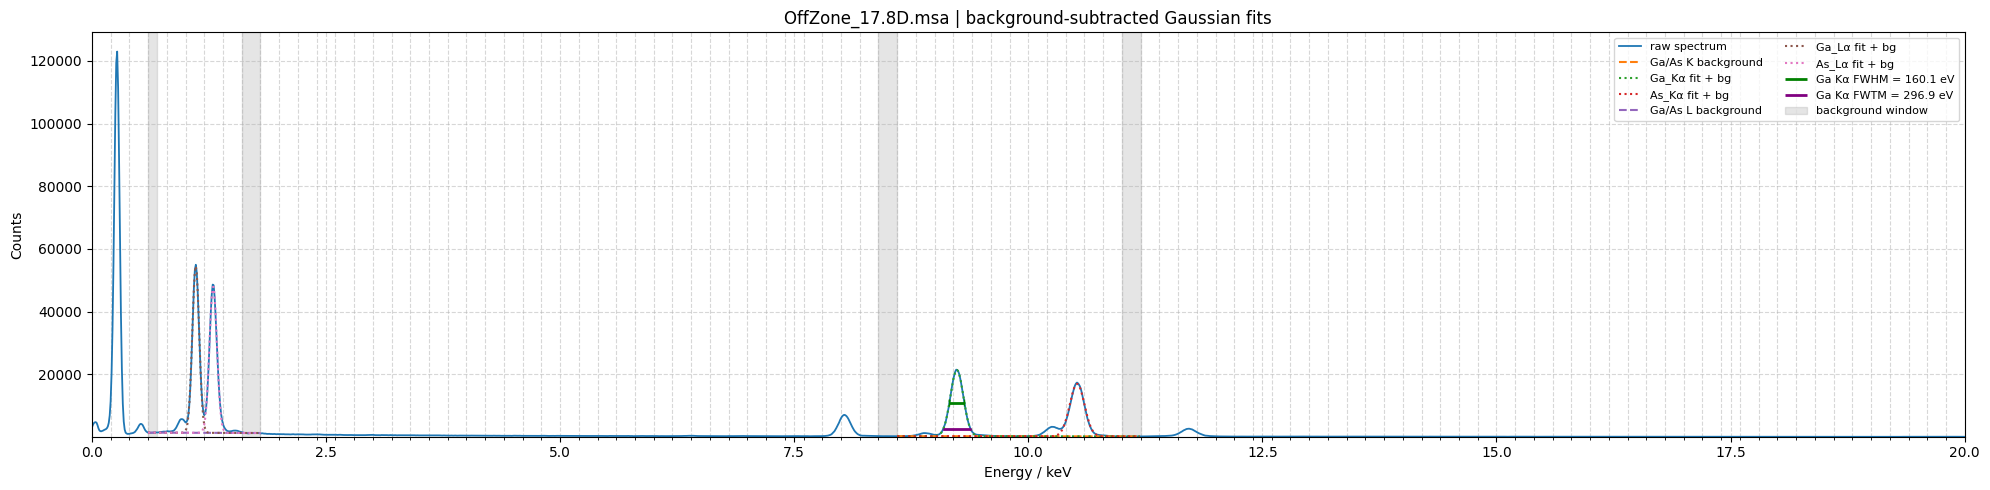

OffZone_17.8D.msa Cu_Kb=8.9009 keV, Ga_Ka=9.2375 keV, As_Ka=10.5214 keV, Ga_La=1.1090 keV, As_La=1.2953 keV, Cu_Kb=17842.0 Counts/Peak, Ga_Ka=365314.0 Counts/Peak, As_Ka=328758.8 Counts/Peak, Ga_La=489854.3 Counts/Peak, As_La=467952.6 Counts/Peak


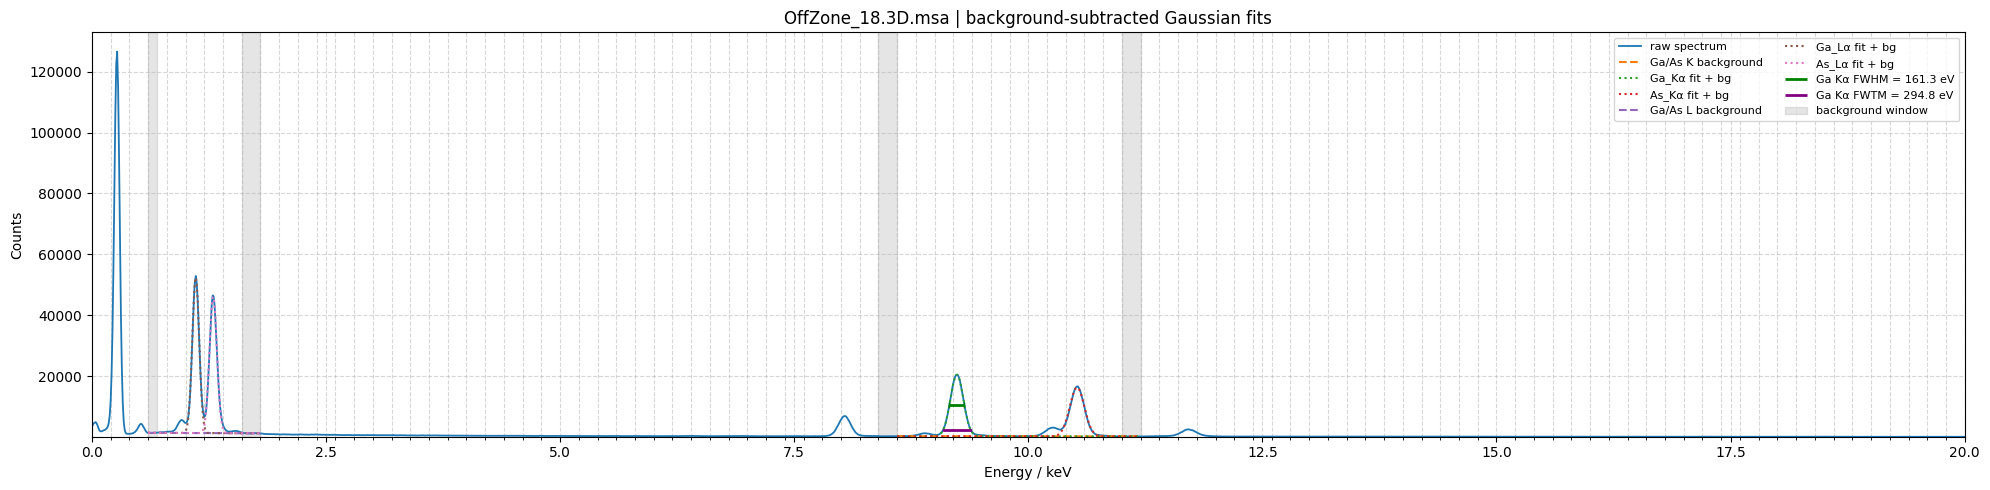

OffZone_18.3D.msa Cu_Kb=8.9005 keV, Ga_Ka=9.2376 keV, As_Ka=10.5211 keV, Ga_La=1.1091 keV, As_La=1.2955 keV, Cu_Kb=17679.9 Counts/Peak, Ga_Ka=350895.4 Counts/Peak, As_Ka=314095.5 Counts/Peak, Ga_La=471030.4 Counts/Peak, As_La=448305.1 Counts/Peak


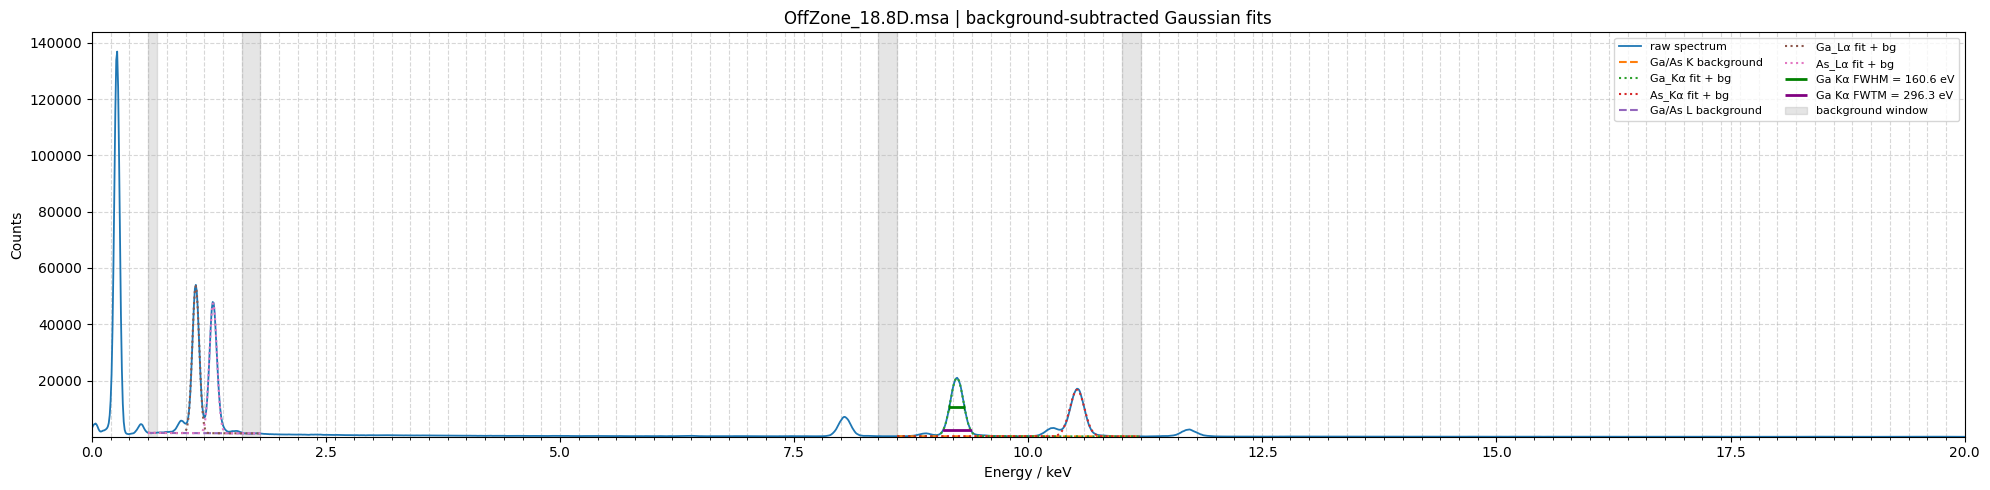

OffZone_18.8D.msa Cu_Kb=8.9007 keV, Ga_Ka=9.2375 keV, As_Ka=10.5215 keV, Ga_La=1.1091 keV, As_La=1.2954 keV, Cu_Kb=17874.6 Counts/Peak, Ga_Ka=359170.8 Counts/Peak, As_Ka=322863.9 Counts/Peak, Ga_La=483215.4 Counts/Peak, As_La=461868.7 Counts/Peak


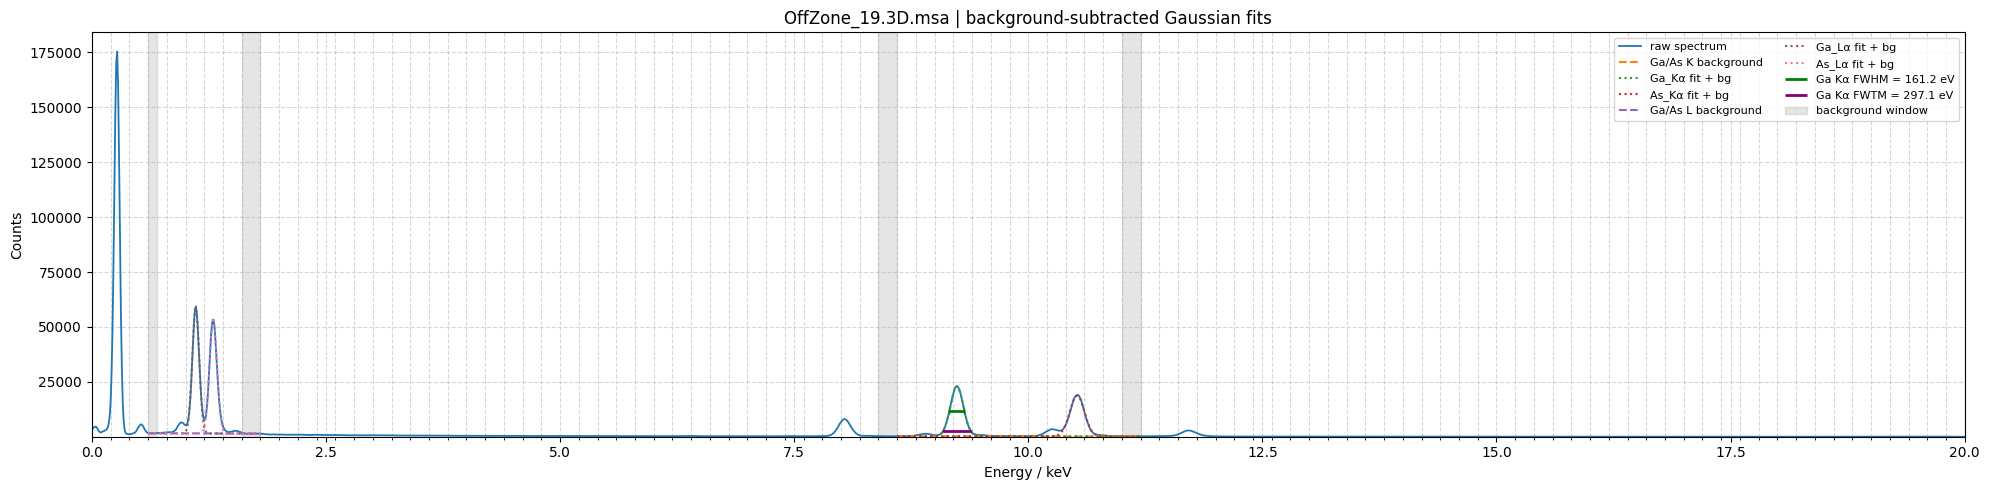

OffZone_19.3D.msa Cu_Kb=8.9019 keV, Ga_Ka=9.2377 keV, As_Ka=10.5213 keV, Ga_La=1.1090 keV, As_La=1.2955 keV, Cu_Kb=20231.3 Counts/Peak, Ga_Ka=395403.0 Counts/Peak, As_Ka=364533.2 Counts/Peak, Ga_La=529255.0 Counts/Peak, As_La=518342.0 Counts/Peak


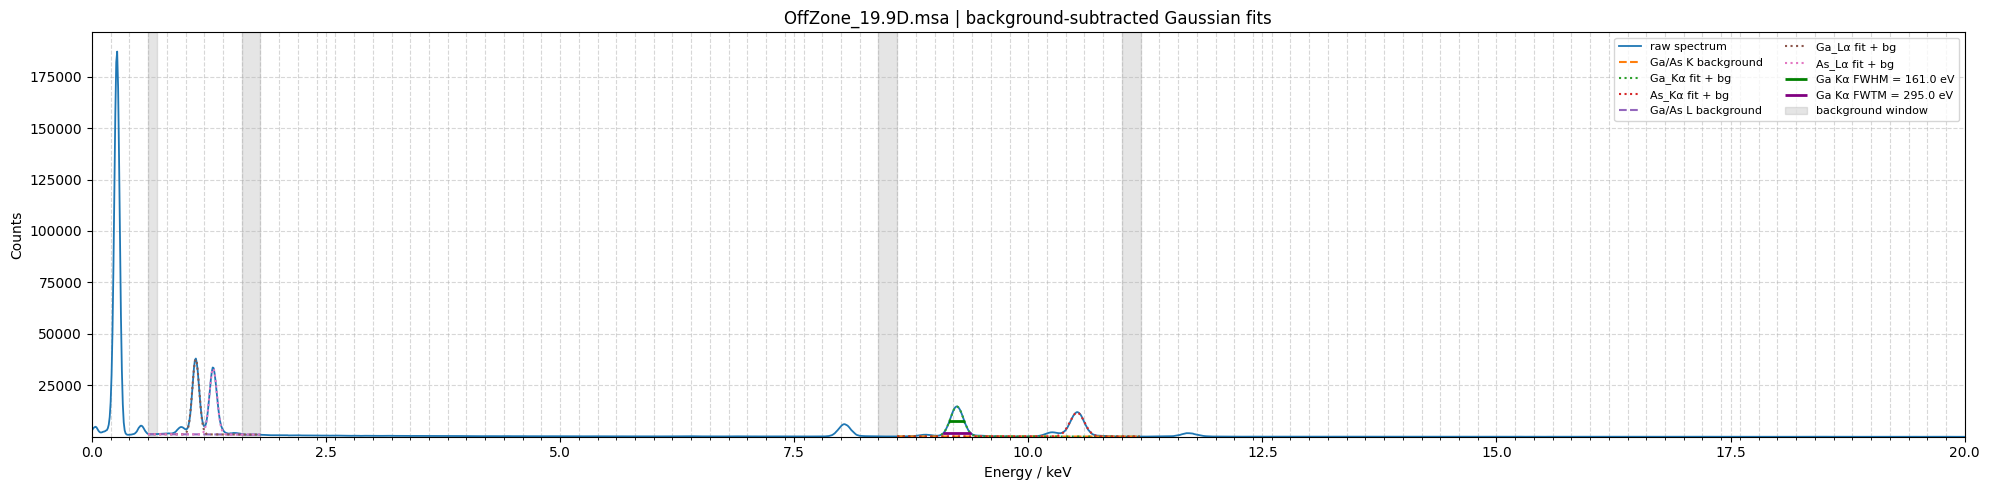

OffZone_19.9D.msa Cu_Kb=8.9031 keV, Ga_Ka=9.2375 keV, As_Ka=10.5212 keV, Ga_La=1.1089 keV, As_La=1.2955 keV, Cu_Kb=15209.0 Counts/Peak, Ga_Ka=252083.1 Counts/Peak, As_Ka=226312.5 Counts/Peak, Ga_La=336240.7 Counts/Peak, As_La=321873.6 Counts/Peak


In [14]:
# ================================================================================================== Area of Gaussian ==================================================================================================

fit_results = []


def gauss(x, A, mu, sig):
    return A * np.exp(-(x - mu)**2 / (2 * sig**2))


def two_gauss(x, A1, mu1, sig1, A2, mu2, sig2):
    return gauss(x, A1, mu1, sig1) + gauss(x, A2, mu2, sig2)


def three_gauss(x, A1, mu1, sig1, A2, mu2, sig2, A3, mu3, sig3):
    return (
        gauss(x, A1, mu1, sig1)
        + gauss(x, A2, mu2, sig2)
        + gauss(x, A3, mu3, sig3)
    )


def area_gauss(A, sig):
    return A * sig * np.sqrt(2 * np.pi)


def width_at_fraction(x, y, fraction):
    y0 = np.min(y)
    y = y - y0
    level = fraction * np.max(y)
    imax = np.argmax(y)

    left = np.where(y[:imax] < level)[0]
    right = np.where(y[imax:] < level)[0] + imax

    if len(left) == 0 or len(right) == 0:
        return np.nan, np.nan, np.nan, np.nan

    i1, i2 = left[-1], left[-1] + 1
    j2, j1 = right[0], right[0] - 1

    x_left = np.interp(level, [y[i1], y[i2]], [x[i1], x[i2]])
    x_right = np.interp(level, [y[j2], y[j1]], [x[j2], x[j1]])

    return x_right - x_left, x_left, x_right, level + y0


# ================================================================================================= Main loop over all spectra =================================================================================================

for f in files:

    # Load spectrum ================================================================================================================================================================================

    s = hs.load(f)
    s.set_signal_type("EDS_TEM")
    s.set_elements(['Ga', 'As'])
    s.set_lines(['Ga_Ka', 'As_Ka', 'Ga_La', 'As_La'])

    x = s.axes_manager.signal_axes[0].axis
    y = s.data.astype(float)

    # Define fit ranges ================================================================================================================================================================================
    # K-region includes Cu_Kb, Ga_Ka and As_Ka

    K_fit_min, K_fit_max = 8.6, rmax_K
    L_fit_min, L_fit_max = lmin_L, rmax_L

    # Create masks for fitting regions ================================================================================================================================================================================

    K_mask = (x >= K_fit_min) & (x <= K_fit_max)
    L_mask = (x >= L_fit_min) & (x <= L_fit_max)

    x_K, y_K = x[K_mask], y[K_mask]
    x_L, y_L = x[L_mask], y[L_mask]

    # Define background windows ================================================================================================================================================================================
    # Important: As_K background is also used for Cu_Kb and Ga_Ka

    bg_mask_K = ((x >= lmin_K) & (x <= lmax_K)) | ((x >= rmin_K) & (x <= rmax_K))
    bg_mask_L = ((x >= lmin_L) & (x <= lmax_L)) | ((x >= rmin_L) & (x <= rmax_L))

    # Fit linear background ================================================================================================================================================================================

    p_K = np.polyfit(x[bg_mask_K], y[bg_mask_K], 1)
    p_L = np.polyfit(x[bg_mask_L], y[bg_mask_L], 1)

    bg_K = np.polyval(p_K, x_K)
    bg_L = np.polyval(p_L, x_L)

    # Background subtraction ================================================================================================================================================================================

    y_K_sub = np.clip(y_K - bg_K, 0, None)
    y_L_sub = np.clip(y_L - bg_L, 0, None)

    # Gaussian fits ================================================================================================================================================================================

    # Cu Kβ + Ga Kα + As Kα
    # Cu_Kb ≈ 8.90 keV
    # Ga_Ka ≈ 9.25 keV
    # As_Ka ≈ 10.54 keV

    p0_K = [
        y_K_sub.max() * 0.5, 8.90, 0.07,    # Cu_Kb
        y_K_sub.max() * 0.4, 9.25, 0.07,    # Ga_Ka
        y_K_sub.max(),       10.54, 0.07    # As_Ka
    ]

    bounds_K = ([0, 8.75, 0.01, 0, 9.10, 0.01, 0, 10.30, 0.01],[np.inf, 9.05, 0.25, np.inf, 9.45, 0.25, np.inf, 10.75, 0.25])

    popt_K, _ = curve_fit(three_gauss,x_K, y_K_sub, p0=p0_K,bounds=bounds_K, maxfev=50000)

    A_Cu_Kb, mu_Cu_Kb, sig_Cu_Kb, A_Ga_Ka, mu_Ga_Ka, sig_Ga_Ka, A_As_Ka, mu_As_Ka, sig_As_Ka = popt_K

    # Ga Lα + As Lα
    # Ga_La ≈ 1.10 keV
    # As_La ≈ 1.28 keV

    p0_L = [y_L_sub.max() * 0.8, 1.10, 0.04, y_L_sub.max(), 1.28, 0.04]

    bounds_L = ([0, 1.03, 0.005, 0, 1.20, 0.005], [np.inf, 1.17, 0.15, np.inf, 1.35, 0.15])

    popt_L, _ = curve_fit(two_gauss,x_L,y_L_sub,p0=p0_L,bounds=bounds_L,maxfev=50000)

    A_Ga_La, mu_Ga_La, sig_Ga_La, A_As_La, mu_As_La, sig_As_La = popt_L

    # Data-based FWHM/FWTM for Ga Kα ================================================================================================================================================================================

    Ga_Ka_mask = (x_K >= mu_Ga_Ka - 0.4) & (x_K <= mu_Ga_Ka + 0.4)
    x_Ga_Ka_only = x_K[Ga_Ka_mask]
    y_Ga_Ka_only = y_K_sub[Ga_Ka_mask]

    FWHM_Ga_Ka_data, x_FWHM_left, x_FWHM_right, y_FWHM_level = width_at_fraction(x_Ga_Ka_only, y_Ga_Ka_only, 0.5)
    FWTM_Ga_Ka_data, x_FWTM_left, x_FWTM_right, y_FWTM_level = width_at_fraction(x_Ga_Ka_only, y_Ga_Ka_only, 0.1)

    # Peak areas ================================================================================================================================================================================

    KeV_per_channel = 1 / s.axes_manager.signal_axes[0].scale

    area_Cu_Kb = area_gauss(A_Cu_Kb, sig_Cu_Kb) * KeV_per_channel
    area_Ga_Ka = area_gauss(A_Ga_Ka, sig_Ga_Ka) * KeV_per_channel
    area_As_Ka = area_gauss(A_As_Ka, sig_As_Ka) * KeV_per_channel
    area_Ga_La = area_gauss(A_Ga_La, sig_Ga_La) * KeV_per_channel
    area_As_La = area_gauss(A_As_La, sig_As_La) * KeV_per_channel

    # Store results ================================================================================================================================================================================

    fit_results.append({
        "file": f,
        "angle": extract_angle(f),

        "Cu_Kb_mu": mu_Cu_Kb,
        "Ga_Ka_mu": mu_Ga_Ka,
        "As_Ka_mu": mu_As_Ka,
        "Ga_La_mu": mu_Ga_La,
        "As_La_mu": mu_As_La,

        "Cu_Kb_area": area_Cu_Kb,
        "Ga_Ka_area": area_Ga_Ka,
        "As_Ka_area": area_As_Ka,
        "Ga_La_area": area_Ga_La,
        "As_La_area": area_As_La,

        "K_background_windows": (lmin_K, lmax_K, rmin_K, rmax_K),
        "L_background_windows": (lmin_L, lmax_L, rmin_L, rmax_L),

        "K_background_poly": p_K,
        "L_background_poly": p_L,

        "Cu_Kb_sig": sig_Cu_Kb,
        "Ga_Ka_sig": sig_Ga_Ka,
        "As_Ka_sig": sig_As_Ka,
        "Ga_La_sig": sig_Ga_La,
        "As_La_sig": sig_As_La,

        "Ga_Ka_FWHM_data": FWHM_Ga_Ka_data,
        "Ga_Ka_FWTM_data": FWTM_Ga_Ka_data,
    })

    # ----------------------------------------------------------------------------------------------
    # Plot spectrum, background and Gaussian fits
    # ----------------------------------------------------------------------------------------------

    fig, ax = plt.subplots(figsize=(20, 5))
    ax.plot(x, y, label="raw spectrum", linewidth=1.3)

    # Cu Kβ / Ga Kα / As Kα plot
    xK_plot = x[(x >= K_fit_min) & (x <= K_fit_max)]
    bgK_plot = np.polyval(p_K, xK_plot)

    Cu_Kb_plot = gauss(xK_plot, A_Cu_Kb, mu_Cu_Kb, sig_Cu_Kb)
    Ga_Ka_plot = gauss(xK_plot, A_Ga_Ka, mu_Ga_Ka, sig_Ga_Ka)
    As_Ka_plot = gauss(xK_plot, A_As_Ka, mu_As_Ka, sig_As_Ka)

    ax.plot(xK_plot, bgK_plot, "--", label="Ga/As K background")
    #ax.plot(xK_plot, bgK_plot + Cu_Kb_plot, ":", label="Cu_Kβ fit + bg")
    ax.plot(xK_plot, bgK_plot + Ga_Ka_plot, ":", label="Ga_Kα fit + bg")
    ax.plot(xK_plot, bgK_plot + As_Ka_plot, ":", label="As_Kα fit + bg")

    # Ga Lα / As Lα plot
    xL_plot = x[(x >= L_fit_min) & (x <= L_fit_max)]
    bgL_plot = np.polyval(p_L, xL_plot)

    Ga_La_plot = gauss(xL_plot, A_Ga_La, mu_Ga_La, sig_Ga_La)
    As_La_plot = gauss(xL_plot, A_As_La, mu_As_La, sig_As_La)

    ax.plot(xL_plot, bgL_plot, "--", label="Ga/As L background")
    ax.plot(xL_plot, bgL_plot + Ga_La_plot, ":", label="Ga_Lα fit + bg")
    ax.plot(xL_plot, bgL_plot + As_La_plot, ":", label="As_Lα fit + bg")

    # FWHM / FWTM markers for Ga Kα
    y_FWHM_plot = np.polyval(p_K, (x_FWHM_left + x_FWHM_right) / 2) + y_FWHM_level
    y_FWTM_plot = np.polyval(p_K, (x_FWTM_left + x_FWTM_right) / 2) + y_FWTM_level

    ax.hlines(y_FWHM_plot, x_FWHM_left, x_FWHM_right, color="green", linewidth=2, label=f"Ga Kα FWHM = {FWHM_Ga_Ka_data*1000:.1f} eV")
    ax.hlines(y_FWTM_plot, x_FWTM_left, x_FWTM_right, color="purple", linewidth=2, label=f"Ga Kα FWTM = {FWTM_Ga_Ka_data*1000:.1f} eV")
    ax.vlines([x_FWHM_left, x_FWHM_right], y_FWHM_plot*0.9, y_FWHM_plot*1.1, color="green", linewidth=1)
    ax.vlines([x_FWTM_left, x_FWTM_right], y_FWTM_plot*0.9, y_FWTM_plot*1.1, color="purple", linewidth=1)

    # Background windows
    ax.axvspan(lmin_K, lmax_K, color="grey", alpha=0.2, label="background window")
    ax.axvspan(rmin_K, rmax_K, color="grey", alpha=0.2)
    ax.axvspan(lmin_L, lmax_L, color="grey", alpha=0.2)
    ax.axvspan(rmin_L, rmax_L, color="grey", alpha=0.2)

    # Plot style
    ax.set_xlabel("Energy / keV")
    ax.set_ylabel("Counts")
    ax.set_title(f"{f.name} | background-subtracted Gaussian fits")
    ax.set_yscale("linear")
    ax.xaxis.set_minor_locator(MultipleLocator(0.2))
    ax.set_xlim(0, 20)
    ax.set_ylim(bottom=60)
    ax.legend(ncol=2, fontsize=8)

    plt.tight_layout()
    plt.grid(True, which="both", ls="--", alpha=0.5)
    plt.show()

    # Print result summary

    print(
        f"{f.name:15} "
        f"Cu_Kb={mu_Cu_Kb:.4f} keV, "
        f"Ga_Ka={mu_Ga_Ka:.4f} keV, "
        f"As_Ka={mu_As_Ka:.4f} keV, "
        f"Ga_La={mu_Ga_La:.4f} keV, "
        f"As_La={mu_As_La:.4f} keV, "
        f"Cu_Kb={area_Cu_Kb:.1f} Counts/Peak, "
        f"Ga_Ka={area_Ga_Ka:.1f} Counts/Peak, "
        f"As_Ka={area_As_Ka:.1f} Counts/Peak, "
        f"Ga_La={area_Ga_La:.1f} Counts/Peak, "
        f"As_La={area_As_La:.1f} Counts/Peak"
    )

$$
\frac{C_{\mathrm{As}}}{C_{\mathrm{Ga}}} = k_{\mathrm{As/Ga}} \cdot \frac{A_{\mathrm{As}}}{A_{\mathrm{Ga}}}
$$
With C as the Composition and A as Area below the peak But this this the weighted composition not the Atomic composition 
$$
k_{\mathrm{As/Ga}}=\frac{k_{\mathrm{As/Si}}}{k_{\mathrm{Ga/Si}}} \cdot CalibrationFactor
$$
For Atomic Composition you need to multiply the inversed Mass ratio
$$
CalibrationFactor \approx \frac{Atomic Mass Gallium}{Atomic Mass Arsenite}=\frac{69.72}{74.92}=0.9306
$$
But the calibration will be slightly adapted in that way that the coomposition  averages about

In [15]:
#============================================================================================ Composition Calculation =================================================================================================================



results = []

# reload only if you update the k_factors, otherwise you can just import it once at the top of the notebook
# import importlib
# import organized.k_factors as kf_module
# importlib.reload(kf_module)
# k_factors = kf_module.k_factors

# HERE HERE HERE HERE HERE HERE HERE HERE HERE HERE HERE HERE HERE HERE HERE HERE HERE HERE HERE HERE HERE HERE HERE HERE HERE HERE HERE HERE HERE HERE

Calibraioin_Factor = 0.9306  # Mass ratio of Ga and As 69.72/74.92 = 0.9306

# HERE HERE HERE HERE HERE HERE HERE HERE HERE HERE HERE HERE HERE HERE HERE HERE HERE HERE HERE HERE HERE HERE HERE HERE HERE HERE HERE HERE HERE HERE

k_AsGa = ((k_factors["As_Ka"] / k_factors["Ga_Ka"])* Calibraioin_Factor)

print("k_(As_Ka/Si_Ka) =", k_factors["As_Ka"], ", k_(Ga_Ka/Si_Ka) =", k_factors["Ga_Ka"], ", k_(As_Ka/Ga_Ka)_Calibrated =", k_AsGa)

print()

# ------------------------------------------------------------------
# determine k-factor that gives average composition of exactly 50/50
# ------------------------------------------------------------------

k_AsGa_50_50 = k_AsGa


# refinement loop # get better results for higher numbers

for i in range(10): # CHANGE THIS NUMBER TO GET BETTER RESULTS, BUT IT ALSO INCREASES THE CALCULATION TIME, 4 IS A GOOD COMPROMISE

    temp_as_comps = []

    for fit in fit_results:

        area_ga = fit["Ga_Ka_area"]
        area_as = fit["As_Ka_area"]

        As_Composition = (k_AsGa_50_50* (area_as / area_ga))

        As_comp_final = (As_Composition / (1 + As_Composition)* 100)

        temp_as_comps.append(As_comp_final)

    as_avg_temp = np.mean(temp_as_comps)

    # correction
    k_AsGa_50_50 = (k_AsGa_50_50* (50 / as_avg_temp))

print(f"k_AsGa for average 50/50 composition = "f"{k_AsGa_50_50:.6f}")

print()

# ------------------------------------------------------------------
# calculate composition for each fit result
# ------------------------------------------------------------------

for fit in fit_results:

    area_ga = fit["Ga_Ka_area"]
    area_as = fit["As_Ka_area"]

    Ga_Composition = 1

    As_Composition = (k_AsGa_50_50 * (area_as / area_ga)* Ga_Composition)

    Ga_comp_final = (Ga_Composition/ (Ga_Composition + As_Composition)* 100)

    As_comp_final = (As_Composition/ (Ga_Composition + As_Composition)* 100)

    results.append({
        "file": fit["file"].name,
        "angle": fit["angle"],
        "Ga_Ka": area_ga,
        "As_Ka": area_as,
        "Ga_comp": Ga_comp_final,
        "As_comp": As_comp_final,
    })

    print(
        f"{fit['file'].name:10}  "
        f"Ga_Composition: {Ga_comp_final:.2f} at.%, "
        f"As_Composition: {As_comp_final:.2f} at.%   "
        f"Ga_Ka_Area={area_ga:.1f}, "
        f"As_Ka_Area={area_as:.1f}, "
        f"As_Ka/Ga_Ka={area_as/area_ga:.3f}"
    )

# ------------------------------------------------------------------
# averages
# ------------------------------------------------------------------

ga_avg = np.mean([r["Ga_comp"] for r in results])
as_avg = np.mean([r["As_comp"] for r in results])

ga_area_avg = np.mean([r["Ga_Ka"] for r in results])
as_area_avg = np.mean([r["As_Ka"] for r in results])

print()

print(
    f"{'AVERAGE':10}  "
    f"Ga_Composition: {ga_avg:.2f} at.%, "
    f"As_Composition: {as_avg:.2f} at.%   "
    f"Ga_Ka_Area={ga_area_avg:.1f}, "
    f"As_Ka_Area={as_area_avg:.1f}, "
    f"As_Ka/Ga_Ka={as_area_avg/ga_area_avg:.3f}"
)


k_(As_Ka/Si_Ka) = 1.31 , k_(Ga_Ka/Si_Ka) = 1.199 , k_(As_Ka/Ga_Ka)_Calibrated = 1.0167522935779818

k_AsGa for average 50/50 composition = 1.093296

OffZone_10.0D.msa  Ga_Composition: 48.11 at.%, As_Composition: 51.89 at.%   Ga_Ka_Area=405238.3, As_Ka_Area=399739.5, As_Ka/Ga_Ka=0.986
OffZone_10.5D.msa  Ga_Composition: 50.05 at.%, As_Composition: 49.95 at.%   Ga_Ka_Area=303606.8, As_Ka_Area=277118.1, As_Ka/Ga_Ka=0.913
OffZone_11.0D.msa  Ga_Composition: 49.82 at.%, As_Composition: 50.18 at.%   Ga_Ka_Area=373720.0, As_Ka_Area=344325.0, As_Ka/Ga_Ka=0.921
OffZone_11.5D.msa  Ga_Composition: 49.58 at.%, As_Composition: 50.42 at.%   Ga_Ka_Area=390382.4, As_Ka_Area=363123.8, As_Ka/Ga_Ka=0.930
OffZone_12.0D.msa  Ga_Composition: 50.05 at.%, As_Composition: 49.95 at.%   Ga_Ka_Area=367784.1, As_Ka_Area=335728.7, As_Ka/Ga_Ka=0.913
OffZone_12.5D.msa  Ga_Composition: 49.86 at.%, As_Composition: 50.14 at.%   Ga_Ka_Area=347114.5, As_Ka_Area=319314.2, As_Ka/Ga_Ka=0.920
OffZone_13.1D.msa  Ga_Composition: 

<center>

# Scale and Offset Calibration:
</center>
Following the Spectrum will be Calibarated with the The Gallium  L-alpha and the K-alpha peak. 
First the first peak will be shifted to the expected spot. That the Energy of L-alpha peak matches the Literature values. Then the bin width, which is before 2eV will be adjusted that also K-alpha peak matches the Literature values. Afterwards the new Offset value and the new Binwidth will be printed.

Idealy the claibration will be done with the a calibration Sample like NiO. The peaks should idealy be spread far from each other and be relativly isolated. 

In [16]:
# ================================================================================================== Scale and Offset Calibration ===================================================================================================
calibrated_spectra = []

# true energies / keV
E_Ga_La_true = s._get_line_energy("Ga_La")
E_As_Ka_true = s._get_line_energy("As_Ka")

print(f"Amount of Channels: {s.axes_manager.signal_axes[0].size}, Channel Width: {s.axes_manager.signal_axes[0].scale:.6f} keV/channel")

for fit in fit_results:
    f = fit["file"]

    s = hs.load(f)
    s.set_signal_type("EDS_TEM")

    ax = s.axes_manager.signal_axes[0]

    # measured peak positions from Gaussian fits
    E_Ga_La_meas = fit["Ga_La_mu"]
    E_As_Ka_meas = fit["As_Ka_mu"]

    # linear calibration: E_true = a * E_meas + b
    a = (E_As_Ka_true - E_Ga_La_true) / (E_As_Ka_meas - E_Ga_La_meas)
    b = E_Ga_La_true - a * E_Ga_La_meas

    old_scale = ax.scale
    old_offset = ax.offset

    ax.scale = old_scale * a
    ax.offset = a * old_offset + b

    calibrated_spectra.append((f, s))

    print(
        f"{f.name:12}  "
        f"Ga_La_meas={E_Ga_La_meas:.4f} keV, "
        f"As_Ka_meas={E_As_Ka_meas:.4f} keV   "
        f"new bin_width={ax.scale:.6f} keV/bin, "
        f"new offset={ax.offset:.6f} keV"
    )

Amount of Channels: 2048, Channel Width: 0.010000 keV/channel
OffZone_10.0D.msa  Ga_La_meas=1.1088 keV, As_Ka_meas=10.5211 keV   new bin_width=0.010035 keV/bin, new offset=-0.215467 keV
OffZone_10.5D.msa  Ga_La_meas=1.1087 keV, As_Ka_meas=10.5210 keV   new bin_width=0.010035 keV/bin, new offset=-0.215328 keV
OffZone_11.0D.msa  Ga_La_meas=1.1090 keV, As_Ka_meas=10.5209 keV   new bin_width=0.010036 keV/bin, new offset=-0.215641 keV
OffZone_11.5D.msa  Ga_La_meas=1.1088 keV, As_Ka_meas=10.5210 keV   new bin_width=0.010036 keV/bin, new offset=-0.215463 keV
OffZone_12.0D.msa  Ga_La_meas=1.1089 keV, As_Ka_meas=10.5209 keV   new bin_width=0.010036 keV/bin, new offset=-0.215576 keV
OffZone_12.5D.msa  Ga_La_meas=1.1089 keV, As_Ka_meas=10.5211 keV   new bin_width=0.010036 keV/bin, new offset=-0.215569 keV
OffZone_13.1D.msa  Ga_La_meas=1.1088 keV, As_Ka_meas=10.5213 keV   new bin_width=0.010035 keV/bin, new offset=-0.215421 keV
OffZone_13.6D.msa  Ga_La_meas=1.1089 keV, As_Ka_meas=10.5209 keV   new

Composition Plot

k_AsGa calibrated = 1.016752
k_AsGa for average 50/50 composition = 1.093296

OffZone_10.0D.msa  Angle=+10.00°, Ga=48.11 at.%, As=51.89 at.%, Ga_Ka=405238.3, As_Ka=399739.5, As/Ga=0.986
OffZone_10.5D.msa  Angle=+10.50°, Ga=50.05 at.%, As=49.95 at.%, Ga_Ka=303606.8, As_Ka=277118.1, As/Ga=0.913
OffZone_11.0D.msa  Angle=+11.00°, Ga=49.82 at.%, As=50.18 at.%, Ga_Ka=373720.0, As_Ka=344325.0, As/Ga=0.921
OffZone_11.5D.msa  Angle=+11.50°, Ga=49.58 at.%, As=50.42 at.%, Ga_Ka=390382.4, As_Ka=363123.8, As/Ga=0.930
OffZone_12.0D.msa  Angle=+12.00°, Ga=50.05 at.%, As=49.95 at.%, Ga_Ka=367784.1, As_Ka=335728.7, As/Ga=0.913
OffZone_12.5D.msa  Angle=+12.50°, Ga=49.86 at.%, As=50.14 at.%, Ga_Ka=347114.5, As_Ka=319314.2, As/Ga=0.920
OffZone_13.1D.msa  Angle=+13.10°, Ga=49.40 at.%, As=50.60 at.%, Ga_Ka=383657.6, As_Ka=359462.1, As/Ga=0.937
OffZone_13.6D.msa  Angle=+13.60°, Ga=50.81 at.%, As=49.19 at.%, Ga_Ka=324006.5, As_Ka=286867.1, As/Ga=0.885
OffZone_14.1D.msa  Angle=+14.10°, Ga=50.35 at.%, As=49.65 

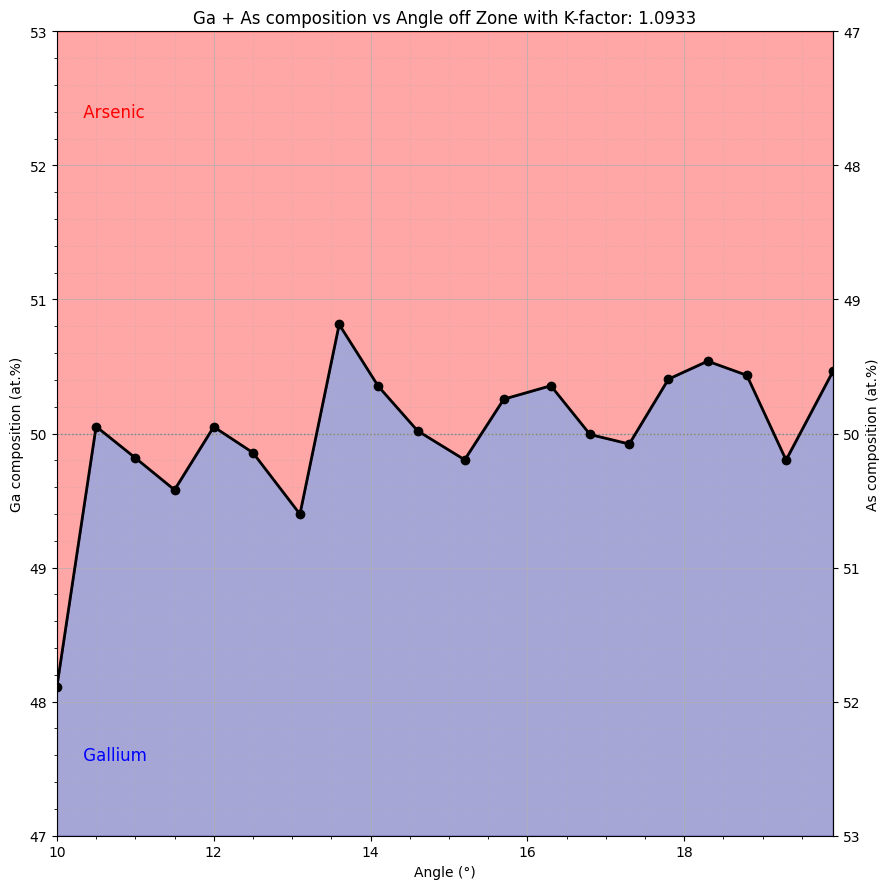

In [19]:
#============================================================================================ Composition Calculation + Plot ============================================================================================

results = []

Calibration_Factor = 0.9306  # Mass ratio Ga/As = 69.72 / 74.92
k_AsGa = (k_factors["As_Ka"] / k_factors["Ga_Ka"]) * Calibration_Factor

print(f"k_AsGa calibrated = {k_AsGa:.6f}")

# ------------------------------------------------------------------
# determine k-factor that gives average composition of exactly 50/50
# ------------------------------------------------------------------

k_AsGa_50_50 = k_AsGa

for i in range(10):
    temp_as = []

    for fit in fit_results:
        area_ga = fit["Ga_Ka_area"]
        area_as = fit["As_Ka_area"]

        ratio = k_AsGa_50_50 * (area_as / area_ga)
        temp_as.append(ratio / (1 + ratio) * 100)

    k_AsGa_50_50 *= 50 / np.mean(temp_as)

print(f"k_AsGa for average 50/50 composition = {k_AsGa_50_50:.6f}")
print()


for fit in fit_results:
    area_ga = fit["Ga_Ka_area"]
    area_as = fit["As_Ka_area"]

    ratio = k_AsGa_50_50 * (area_as / area_ga)

    ga_comp = 100 / (1 + ratio)
    as_comp = 100 - ga_comp

    results.append({
        "file": fit["file"].name,
        "angle": fit["angle"],
        "Ga_Ka": area_ga,
        "As_Ka": area_as,
        "Ga_comp": ga_comp,
        "As_comp": as_comp,
        "As_Ka/Ga_Ka": area_as / area_ga
    })

results = sorted(results, key=lambda r: r["angle"])

for r in results:
    print(
        f"{r['file']:10}  "
        f"Angle={r['angle']:+.2f}°, "
        f"Ga={r['Ga_comp']:.2f} at.%, "
        f"As={r['As_comp']:.2f} at.%, "
        f"Ga_Ka={r['Ga_Ka']:.1f}, "
        f"As_Ka={r['As_Ka']:.1f}, "
        f"As/Ga={r['As_Ka/Ga_Ka']:.3f}"
    )

print()

ga_avg = np.mean([r["Ga_comp"] for r in results])
as_avg = np.mean([r["As_comp"] for r in results])
ga_area_avg = np.mean([r["Ga_Ka"] for r in results])
as_area_avg = np.mean([r["As_Ka"] for r in results])

print(
    f"{'AVERAGE':10}  "
    f"Ga={ga_avg:.2f} at.%, "
    f"As={as_avg:.2f} at.%, "
    f"Ga_Ka={ga_area_avg:.1f}, "
    f"As_Ka={as_area_avg:.1f}, "
    f"As/Ga={as_area_avg / ga_area_avg:.3f}"
)


#======================================================================================================= Composition Plot =======================================================================================================

timestamp = datetime.now().strftime("%Y-%m-%d_%H-%M-%S")

angles = [r["angle"] for r in results]
ga = [r["Ga_comp"] for r in results]

fig, ax1 = plt.subplots(figsize=(9, 9))

center = 50
centeringRange50 = 3
ymin, ymax = center - centeringRange50, center + centeringRange50

ax1.set_xlim(10, 19.9)
ax1.set_ylim(ymin, ymax)

ax1.fill_between(angles, ga, ymax, color="red", alpha=0.35)
ax1.fill_between(angles, ga, ymin, color="darkblue", alpha=0.35)
ax1.plot(angles, ga, marker="o", linewidth=2, color="black", zorder=3)

ax1.set_xlabel("Angle (°)")
ax1.set_ylabel("Ga composition (at.%)")
ax1.set_title(f"Ga + As composition vs Angle off Zone with K-factor: {k_AsGa_50_50:.4f}")

ax1.minorticks_on()
ax1.grid(which="major", linestyle="-", linewidth=0.5, alpha=1)
ax1.grid(which="minor", linestyle=":", linewidth=0.4, alpha=0.75)

ax1.axvline(0, color="grey", linestyle="--", linewidth=1)
ax1.axhline(center, color="grey", linestyle=":", linewidth=1)

secax = ax1.secondary_yaxis("right", functions=(lambda y: 100 - y, lambda y: 100 - y))
secax.set_ylabel("As composition (at.%)")

ax1.text(min(angles), center + 0.8 * centeringRange50, "     Arsenic", fontsize=12, color="red", va="center")
ax1.text(min(angles), center - 0.8 * centeringRange50, "     Gallium", fontsize=12, color="blue", va="center")

plt.tight_layout()
plt.savefig(PlotPath / f"CompositionVsAngle_{timestamp}.pdf")
plt.show()

k_(As_Ka/Si_Ka) = 1.31 , k_(Ga_Ka/Si_Ka) = 1.199 , k_(As_Ka/Ga_Ka)_Calibrated = 1.0122727272727274

OffZone_10.0D.msa  Ga_comp=50, As_comp=50, k_AsGa=1.0138
OffZone_10.5D.msa  Ga_comp=50, As_comp=50, k_AsGa=1.0956
OffZone_11.0D.msa  Ga_comp=50, As_comp=50, k_AsGa=1.0854
OffZone_11.5D.msa  Ga_comp=50, As_comp=50, k_AsGa=1.0751
OffZone_12.0D.msa  Ga_comp=50, As_comp=50, k_AsGa=1.0955
OffZone_12.5D.msa  Ga_comp=50, As_comp=50, k_AsGa=1.0871
OffZone_13.1D.msa  Ga_comp=50, As_comp=50, k_AsGa=1.0673
OffZone_13.6D.msa  Ga_comp=50, As_comp=50, k_AsGa=1.1295
OffZone_14.1D.msa  Ga_comp=50, As_comp=50, k_AsGa=1.1088
OffZone_14.6D.msa  Ga_comp=50, As_comp=50, k_AsGa=1.0942
OffZone_15.2D.msa  Ga_comp=50, As_comp=50, k_AsGa=1.0848
OffZone_15.7D.msa  Ga_comp=50, As_comp=50, k_AsGa=1.1046
OffZone_16.3D.msa  Ga_comp=50, As_comp=50, k_AsGa=1.1090
OffZone_16.8D.msa  Ga_comp=50, As_comp=50, k_AsGa=1.0930
OffZone_17.3D.msa  Ga_comp=50, As_comp=50, k_AsGa=1.0899
OffZone_17.8D.msa  Ga_comp=50, As_comp=50, k_

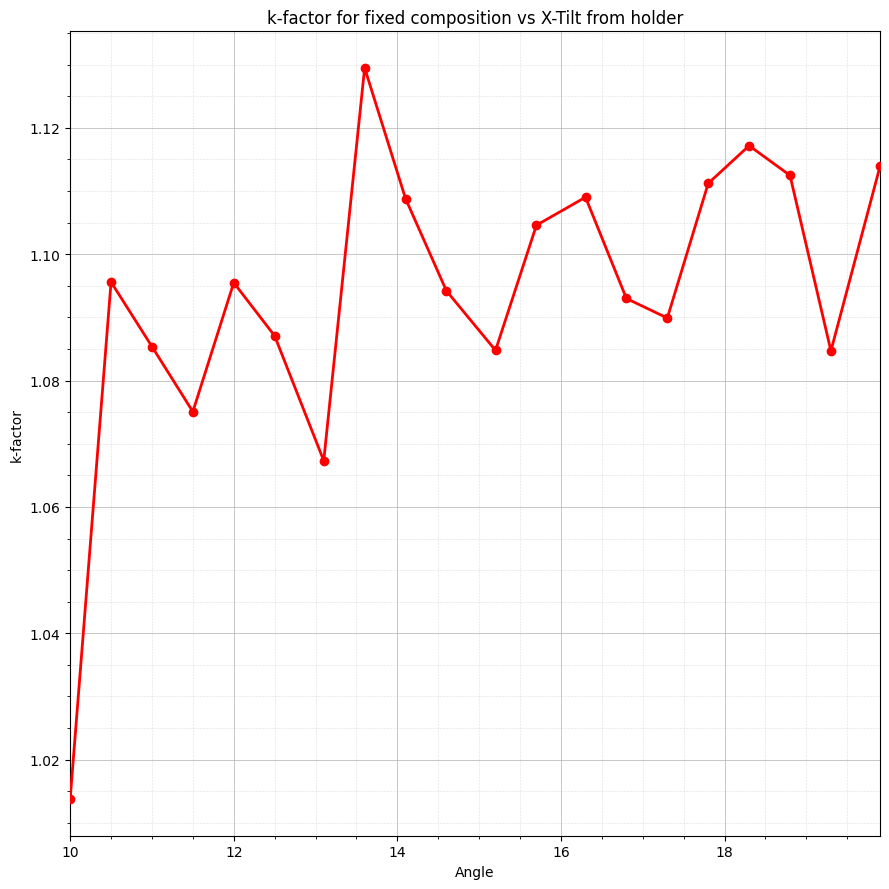

In [20]:
# ================================================================================================== k-factor Calculation with Plot =================================================================================================================

results = []

# HERE HERE HERE HERE HERE HERE HERE HERE HERE HERE HERE HERE HERE HERE HERE HERE HERE HERE HERE HERE HERE HERE HERE HERE HERE HERE HERE HERE HERE HERE

Calibraioin_Factor =0.9265 # Mass ratio of Ga and As 69.72/74.92 = 0.9306

# HERE HERE HERE HERE HERE HERE HERE HERE HERE HERE HERE HERE HERE HERE HERE HERE HERE HERE HERE HERE HERE HERE HERE HERE HERE HERE HERE HERE HERE HERE 

k_AsGa = (k_factors["As_Ka"] / k_factors["Ga_Ka"]) * Calibraioin_Factor
#k_AsGa = 1.093

print("k_(As_Ka/Si_Ka) =", k_factors["As_Ka"], ", k_(Ga_Ka/Si_Ka) =", k_factors["Ga_Ka"], ", k_(As_Ka/Ga_Ka)_Calibrated =", k_AsGa)
print()

# fixed composition
Ga_Composition = 50
As_Composition = 50

# calculate k-factor for each fit result

for fit in fit_results:
    area_ga = fit["Ga_Ka_area"]
    area_as = fit["As_Ka_area"]

    # because Ga/As composition is fixed to 50/50:
    # As/Ga = 1 = k_AsGa * (As_Ka/Ga_Ka)
    k_AsGa_result = area_ga / area_as

    results.append({
        "file": fit["file"].name,
        "angle": fit["angle"],
        "Ga_Ka": area_ga,
        "As_Ka": area_as,
        "Ga_comp": Ga_Composition,
        "As_comp": As_Composition,
        "k_AsGa": k_AsGa_result,
    })

    print(
        f"{fit['file'].name:10}  "
        f"Ga_comp={Ga_Composition}, "
        f"As_comp={As_Composition}, "
        f"k_AsGa={k_AsGa_result:.4f}"
    )


ga_area_avg = np.mean([r["Ga_Ka"] for r in results])
as_area_avg = np.mean([r["As_Ka"] for r in results])
k_AsGa_avg = np.mean([r["k_AsGa"] for r in results])

print()
print(
    f"{'AVERAGE':10}  "

    f"Ga_comp={Ga_Composition}, "
    f"As_comp={As_Composition}, "
    f"k_AsGa_avg={k_AsGa_avg:.4f}"
)# ================================================================================================== Angle Dependence k-Factor Plot ===============================================================================================================

timestamp = datetime.now().strftime("%Y-%m-%d_%H-%M-%S")

results = sorted(results, key=lambda r: r["angle"])

angle = [r["angle"] for r in results]
k_values = [r["k_AsGa"] for r in results]

fig, ax1 = plt.subplots(figsize=(9, 9))

center = 3.45
CenteringRange = 0.05
ymin = center - CenteringRange
ymax = center + CenteringRange

#ax1.set_ylim(ymin, ymax)
ax1.set_xlim(10, 19.9)

ymin, ymax = ax1.get_ylim()


ax1.plot(angle, k_values, marker="o", linewidth=2, color="red", zorder=3)

ax1.set_xlabel("Angle")
ax1.set_ylabel("k-factor")
ax1.set_title(f"k-factor for fixed composition vs X-Tilt from holder")

ax1.minorticks_on()
ax1.grid(which="major", linestyle="-", linewidth=0.5, alpha=1)
ax1.grid(which="minor", linestyle=":", linewidth=0.4, alpha=0.75)

ax1.axvline(0, color="grey", linestyle="--", linewidth=1)



plt.tight_layout()
plt.savefig(PlotPath / f"kFactorVsAngle_{timestamp}.pdf")
plt.show()